# Gas de Chaplygin generalizado: dinamica y restricciones observacionales

Modelo de Szydlowski & Czaja, "Stability of FRW cosmology with generalized
Chaplygin gas", Phys. Rev. D 69, 023506 (2004)  [arXiv:astro-ph/0306579].

Practicas preprofesionales 2025-II -- GRACOCC, UNT


## ALCANCE
El archivo hace dos cosas distintas:

- Partes 1-8: re-analisis observacional moderno del modelo, con datos
  actuales de H(z), supernovas Pantheon y muestreo bayesiano. El articulo
  no hace nada parecido: su ajuste a supernovas es solo su seccion V,
  contornos de Delta $\chi^2$ en ($\alpha, A_s$) con $\Omega_m$ FIJO en 0.05 o 0.30,
  sobre 54 SNe de Perlmutter y sin MCMC.

- Partes 9-10: el nucleo del articulo (sus secciones II-IV). El sistema
  dinamico en el plano (H, $\rho$), sus puntos criticos, los autovalores de la
  linealizacion, el primer integral, el retrato de fase, la formulacion
  hamiltoniana y la compactificacion en la esfera de Poincare.

- Parte 11: el modelo UNIFICADO ($\Omega_m$ = 0), que es la version que motiva
  el articulo -- el gas relaciona a la materia oscura y la energia oscura a
  la vez --, y el limite que le impone la formacion de estructura. Por ultimo hacemos algunas conclusiones del modelo

Queda fuera la desingularizacion por blow-up de los dos equilibrios
degenerados del infinito (ver la parte 10).

## EL MODELO
De la ec. (16b) del articulo, la densidad del gas es

$$\rho_{\rm ch}(z) = \rho_{{\rm ch},0}\left[A_s + (1-A_s)(1+z)^{3(1+\alpha)}\right]^{1/(1+\alpha)}$$

con 
$A_s = \frac{A}{\rho_{ch0}^{(1+\alpha)}}$

 Para el universo FRW plano con materia mas
gas se usa la ec. (33) -- no la (18), que no lleva termino de materia:

$$\frac{H(z)^2}{H_0^2}
= \Omega_m (1+z)^3
+ (1-\Omega_m)\Big[A_s + (1-A_s)(1+z)^{3(1+\alpha)}\Big]^{\frac{1}{1+\alpha}}$$

con $0 < \alpha <= 1$ (condicion $c_s <= c$) y $A_s$ en (0,1). Por construccion
H(0) = 1.


## Ojo
Cuando $A_s \to 1$, el gas es una constante cosmologica PARA CUALQUIER $\alpha$, asi que
ahi la verosimilitud es exactamente plana en $\alpha$: el parametro deja de estar
identificado. Como los datos prefieren justamente esa region, la marginal
$p(\alpha)$ queda dominada por el VOLUMEN DEL PRIOR y no por el dato. Su mediana
con barras al 68% no es una medicion. Por eso $\alpha$ se reporta como limite
superior, y la pregunta que si tiene sentido -- si los datos justifican los
parametros extra frente a LCDM -- se responde con AIC/BIC en la parte 7.

Ojo tambien: Cuando $\alpha \to 0$ NO es el limite $\Lambda CDM$ (es $\Lambda$ + polvo, porque con
$\alpha = 0$ se tiene $p = -A$ constante (de la ecuación 9) y $\rho = A + B/a^3$ (de la ecuación 15)). El limite  $\Lambda CDM$ es $A_s \to 1$, para todo $\alpha$.

## Librerías 

In [1]:
from __future__ import annotations

import argparse
import os
import sys
import zipfile
from dataclasses import dataclass

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.integrate import cumulative_trapezoid, solve_ivp
from scipy.linalg import cho_factor, cho_solve
from scipy.optimize import minimize
from scipy.stats import chi2 as chi2_dist

import corner
import emcee

C_LIGHT = 299792.458      # velocidad de la luz [km/s]
Z_GRID_MAX = 3.0          # malla fija de integracion: el resultado no depende
N_GRID = 4096             # del array de z que se pase a la funcion

## 0. Configuracion

In [2]:
@dataclass
class Config:
    """Opciones de ejecucion. Los valores por defecto son los del notebook."""
    pasos: int = 20000
    caminantes: int = 48
    semilla: int = 42
    usar_bao: bool = False
    pantheon: str | None = None
    sin_ajuste: bool = False
    figuras: str | None = None
    sin_ventanas: bool = False
    cache: str | None = None
    # parametros de la parte dinamica (Fig. 2a del articulo)
    alpha_din: float = 1.0
    A_din: float = 1.0
    B_din: float = 1.7


def parsear_argumentos(argv=None) -> Config:
    """Lee la linea de ordenes. Devuelve los valores por defecto si se ejecuta
    de forma interactiva (por ejemplo en la ventana de VS Code), donde argv no
    es el de un script."""
    p = argparse.ArgumentParser(
        description="Gas de Chaplygin generalizado: ajuste y analisis dinamico.",
        formatter_class=argparse.ArgumentDefaultsHelpFormatter)
    p.add_argument("--pasos", type=int, default=20000,
                   help="pasos del MCMC por caminante")
    p.add_argument("--caminantes", type=int, default=48, help="numero de caminantes")
    p.add_argument("--semilla", type=int, default=42, help="semilla aleatoria")
    p.add_argument("--bao", dest="usar_bao", action="store_true",
                   help="incluir los puntos de H(z) derivados de BAO (ver parte 1)")
    p.add_argument("--pantheon", default=None, metavar="RUTA",
                   help="carpeta donde se descomprimio data_Pantheon.zip")
    p.add_argument("--sin-ajuste", action="store_true",
                   help="saltar los MCMC; corre las partes 9, 10 y la teoria de la 11")
    p.add_argument("--figuras", default=None, metavar="DIR",
                   help="guardar las figuras en este directorio")
    p.add_argument("--sin-ventanas", action="store_true",
                   help="no abrir ventanas de figuras")
    p.add_argument("--cache", default=None, metavar="RUTA.npz",
                   help="leer la cadena de aqui si existe, y escribirla si no")
    try:
        ns, _ = p.parse_known_args(argv)
    except SystemExit:          # -h en modo interactivo
        raise
    return Config(pasos=ns.pasos, caminantes=ns.caminantes, semilla=ns.semilla,
                  usar_bao=ns.usar_bao, pantheon=ns.pantheon,
                  sin_ajuste=ns.sin_ajuste, figuras=ns.figuras,
                  sin_ventanas=ns.sin_ventanas, cache=ns.cache)


CFG = Config()            # main() lo sustituye por lo que diga la linea de ordenes
PANTHEON = None           # objeto PantheonData, o None si no se carga


def titulo(texto: str, nivel: int = 1) -> None:
    c = "=" if nivel == 1 else "-"
    print(f"\n{c * 78}\n{texto}\n{c * 78}")


def guardar_figura(fig, nombre: str) -> None:
    if CFG.figuras:
        os.makedirs(CFG.figuras, exist_ok=True)
        ruta = os.path.join(CFG.figuras, f"{nombre}.png")
        fig.savefig(ruta, dpi=130, bbox_inches="tight")
        print(f"   [figura guardada: {ruta}]")

In [ ]:
%matplotlib inline

# Lo que en el script serian las opciones de la linea de ordenes.
CFG = Config(
    pasos=20000,          # 4000 basta para una pasada rapida
    caminantes=48,
    semilla=42,
    usar_bao=False,       # los puntos de H(z) derivados de BAO, fuera (parte 1)
    pantheon="data_Pantheon",  # carpeta con los .txt de Pantheon
    sin_ajuste=False,
    figuras=None,         # directorio donde guardar los PNG
    sin_ventanas=True,    # en el notebook las figuras salen en linea
    cache=None,
)
CFG

## 1. Datos observacionales de H(z)

Hay dos subconjuntos de naturaleza estadistica DISTINTA, que no deben
mezclarse a ciegas:


- **Cronómetros cósmicos** Mide dz/dt a partir de la edad
            diferencial de galaxias pasivas; es independiente del modelo.
- **Supernovas tipo Ia (Pantheon)** derivado de BAO. BAO mide $H(z)*r_d$, no H(z): convertirlo exige
            SUPONER r_d, lo que importa informacion de CMB/BBN y rompe la
            independencia del modelo. Ademas, los puntos de un mismo survey
            estan correlacionados, asi que una covarianza diagonal no vale.


In [4]:
HZ_RAW = np.array([
    #   z        H      sigma  BAO
    [0.070,   69.00, 19.68, 0], [0.090,   69.00, 12.00, 0],
    [0.120,   68.60, 26.20, 0], [0.170,   83.00,  8.00, 0],
    [0.179,   75.00,  4.00, 0], [0.199,   75.00,  5.00, 0],
    [0.200,   72.90, 29.60, 0], [0.240,   79.69,  2.65, 1],
    [0.270,   77.00, 14.00, 0], [0.280,   88.80, 36.60, 0],
    [0.350,   84.40,  7.00, 0], [0.352,   83.00, 14.00, 0],
    [0.400,   95.00, 17.00, 0], [0.430,   86.45,  3.68, 0],
    [0.440,   82.60,  7.80, 0], [0.480,   97.00, 62.00, 0],
    [0.570,   92.40,  4.50, 0], [0.593,  104.00, 13.00, 0],
    [0.600,   87.90,  6.10, 0], [0.680,   92.00,  8.00, 0],
    [0.730,   97.30,  7.00, 0], [0.781,  105.00, 12.00, 0],
    [0.875,  125.00, 17.00, 0], [0.880,   90.00, 40.00, 0],
    [0.900,  117.00, 23.00, 0], [0.922,  115.61,  1.39, 1],
    [0.934,  124.82,  1.51, 1], [0.955,  114.70,  1.91, 1],
    [1.037,  154.00, 20.00, 0], [1.300,  168.00, 17.00, 0],
    [1.321,  149.70,  2.33, 1], [1.363,  160.00, 33.60, 0],
    [1.430,  177.00, 18.00, 0], [1.484,  159.06,  6.40, 0],
    [1.530,  140.00, 14.00, 0], [1.750,  202.00, 40.00, 0],
    [1.965,  186.50, 50.40, 0], [2.300,  224.00,  8.00, 0],
    [2.330,  233.79,  2.73, 1], [2.340,  222.00,  7.00, 0],
    [2.360,  226.00,  8.00, 0],
])

HZ_ALL = HZ_RAW[np.argsort(HZ_RAW[:, 0])]
IS_BAO = HZ_ALL[:, 3].astype(bool)

Z_HZ = H_OBS = H_ERR = None      # los fija seleccionar_datos_hz()


def seleccionar_datos_hz(usar_bao: bool, verboso: bool = True):
    """Fija Z_HZ, H_OBS, H_ERR y, de paso, explica por que los puntos BAO
    quedan fuera por defecto."""
    global Z_HZ, H_OBS, H_ERR

    if verboso:
        titulo("1. Datos observacionales de H(z)")
        w = 1.0 / HZ_ALL[:, 2] ** 2
        print(f"{IS_BAO.sum()} puntos marcados como BAO de {len(HZ_ALL)} totales, "
              f"pero concentran el {100 * w[IS_BAO].sum() / w.sum():.1f}% del peso "
              f"estadistico (1/sigma^2)\n")
        print("consistencia interna de esos puntos")
        print("(a dz~0.01 cualquier cosmologia suave cambia H en <1 km/s/Mpc,")
        print(" asi que dos medidas tan proximas en z deberian coincidir):")
        ib = np.where(IS_BAO)[0]
        for a in range(len(ib)):
            for b in range(a + 1, len(ib)):
                i, j = ib[a], ib[b]
                if abs(HZ_ALL[i, 0] - HZ_ALL[j, 0]) < 0.05:
                    d = abs(HZ_ALL[i, 1] - HZ_ALL[j, 1])
                    s = np.hypot(HZ_ALL[i, 2], HZ_ALL[j, 2])
                    flag = "   <-- INCOMPATIBLES" if d / s > 3 else ""
                    print(f"  z={HZ_ALL[i,0]:.3f} ({HZ_ALL[i,1]:6.2f} +- {HZ_ALL[i,2]:.2f})"
                          f"  vs  z={HZ_ALL[j,0]:.3f} ({HZ_ALL[j,1]:6.2f} +- "
                          f"{HZ_ALL[j,2]:.2f}) : {d:5.2f} = {d/s:.1f} sigma{flag}")

    mask = np.ones(len(HZ_ALL), bool) if usar_bao else ~IS_BAO
    Z_HZ, H_OBS, H_ERR = HZ_ALL[mask, 0], HZ_ALL[mask, 1], HZ_ALL[mask, 2]
    if verboso:
        print(f"\nusar_bao = {usar_bao}  ->  {len(Z_HZ)} puntos en el ajuste, "
              f"z = {Z_HZ.min():.3f} a {Z_HZ.max():.3f}")
    return Z_HZ, H_OBS, H_ERR

#Figuras de los datos de H(z) y de la funcion de ventana
def figura_datos_hz(usar_bao: bool):
    fig = plt.figure(figsize=(8, 5))
    plt.errorbar(HZ_ALL[~IS_BAO, 0], HZ_ALL[~IS_BAO, 1], yerr=HZ_ALL[~IS_BAO, 2],
                 fmt="o", ms=5, capsize=3, color="C0", ecolor="lightsteelblue",
                 label="cronometros cosmicos")
    plt.errorbar(HZ_ALL[IS_BAO, 0], HZ_ALL[IS_BAO, 1], yerr=HZ_ALL[IS_BAO, 2],
                 fmt="s", ms=6, capsize=3, color="C3", ecolor="lightcoral",
                 label=f"derivados de BAO ({'incluidos' if usar_bao else 'excluidos'})")
    plt.xlabel("$z$", fontsize=13)
    plt.ylabel(r"$H(z)\ [\mathrm{km\,s^{-1}\,Mpc^{-1}}]$", fontsize=13)
    plt.title("Datos observacionales de $H(z)$")
    plt.legend(fontsize=9)
    plt.grid(alpha=0.3)
    guardar_figura(fig, "01_datos_hz")
    return fig

Datos de H(z)


1. Datos observacionales de H(z)
6 puntos marcados como BAO de 41 totales, pero concentran el 77.9% del peso estadistico (1/sigma^2)

consistencia interna de esos puntos
(a dz~0.01 cualquier cosmologia suave cambia H en <1 km/s/Mpc,
 asi que dos medidas tan proximas en z deberian coincidir):
  z=0.922 (115.61 +- 1.39)  vs  z=0.934 (124.82 +- 1.51) :  9.21 = 4.5 sigma   <-- INCOMPATIBLES
  z=0.922 (115.61 +- 1.39)  vs  z=0.955 (114.70 +- 1.91) :  0.91 = 0.4 sigma
  z=0.934 (124.82 +- 1.51)  vs  z=0.955 (114.70 +- 1.91) : 10.12 = 4.2 sigma   <-- INCOMPATIBLES

usar_bao = False  ->  35 puntos en el ajuste, z = 0.070 a 2.360


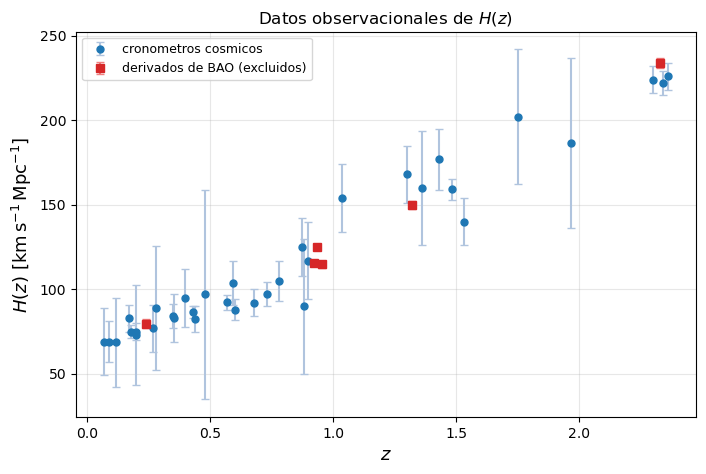

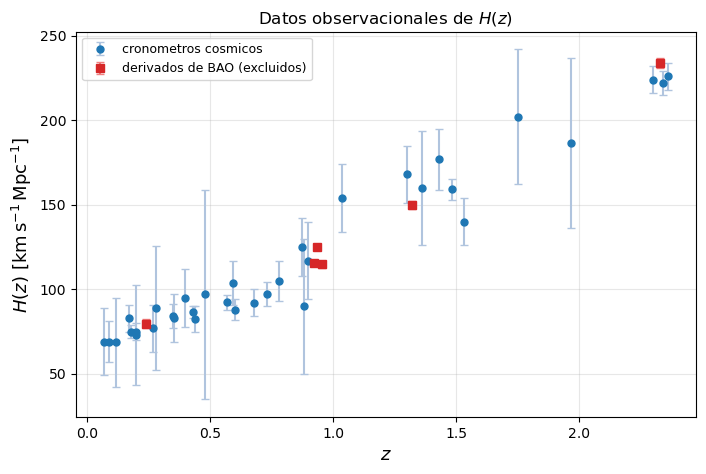

In [5]:
seleccionar_datos_hz(CFG.usar_bao)
figura_datos_hz(CFG.usar_bao)

## 2. El modelo cosmologico

In [6]:
def E_model(z, alpha, As, Om):
    """Funcion de expansion adimensional E(z) = H(z)/H0.

    Devuelve NaN donde el modelo no esta definido (base negativa, alpha = -1),
    lo que la verosimilitud traduce despues en -inf.
    """
    z = np.asarray(z, dtype=float)
    if not np.isfinite(alpha) or np.isclose(1.0 + alpha, 0.0):
        return np.full(z.shape, np.nan)

    base = As + (1.0 - As) * (1.0 + z) ** (3.0 * (1.0 + alpha))
    with np.errstate(invalid="ignore", divide="ignore"):
        chapl = np.where(base > 0, base, np.nan) ** (1.0 / (1.0 + alpha))
        E2 = Om * (1.0 + z) ** 3 + (1.0 - Om) * chapl
        return np.sqrt(np.where(E2 > 0, E2, np.nan))


def H_model(z, alpha, As, H0, Om):
    """H(z) en km/s/Mpc."""
    return H0 * E_model(z, alpha, As, Om)


def luminosity_distance(z, alpha, As, H0, Om, z_max=None, n_grid=N_GRID):
    """Distancia luminosa d_L(z) en Mpc (modelo plano), sobre malla fija.

    La malla es fija a proposito: si se construyera con el max(z) del array de
    entrada, la resolucion -- y por tanto el resultado -- cambiaria segun a que
    subconjunto de redshifts se llamara la funcion.
    """
    z = np.atleast_1d(np.asarray(z, dtype=float))
    zmax = float(z_max if z_max is not None else max(Z_GRID_MAX, np.max(z)))
    zg = np.linspace(0.0, zmax, n_grid)

    Hg = H_model(zg, alpha, As, H0, Om)
    if not np.all(np.isfinite(Hg)) or np.any(Hg <= 0):
        return np.full(z.shape, np.nan)

    dC_grid = np.concatenate(([0.0], cumulative_trapezoid(C_LIGHT / Hg, zg)))
    return (1.0 + z) * np.interp(z, zg, dC_grid)


def distance_modulus(z, alpha, As, H0, Om):
    """mu(z) = 5 log10(d_L / Mpc) + 25."""
    dL = luminosity_distance(z, alpha, As, H0, Om)
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(dL > 0, 5.0 * np.log10(dL) + 25.0, np.nan)


def deceleration_parameter(z, alpha, As, Om, dz=1e-4):
    """q(z) = (1+z) E'(z)/E(z) - 1, por diferencias centradas."""
    E = E_model(z, alpha, As, Om)
    dE = (E_model(z + dz, alpha, As, Om) - E_model(z - dz, alpha, As, Om)) / (2 * dz)
    return (1.0 + z) * dE / E - 1.0

## 3. Verificaciones del modelo

In [7]:
def verificaciones_modelo():
    """Comprueba que el modelo hace lo que debe antes de ajustar nada."""
    titulo("3. Verificaciones del modelo")

    print("1) Normalizacion:  E(0) =", E_model(np.array([0.0]), 0.5, 0.75, 0.3)[0])

    z_test = np.array([0.5, 1.0, 2.0])
    E_lcdm = np.sqrt(0.3 * (1 + z_test) ** 3 + 0.7)

    # Hay que probarlo con VARIOS alpha: con uno solo no se detecta que alpha
    # queda sin identificar en este limite, que es la clave del posterior.
    print("\n2) As -> 1  (debe dar LCDM para todo alpha):")
    for a in (0.05, 0.5, 1.0):
        d = np.max(np.abs(E_model(z_test, a, 1 - 1e-12, 0.3) - E_lcdm))
        print(f"   alpha = {a:<5}  max|E_GCG - E_LCDM| = {d:.3e}")

    print("\n3) alpha -> 0  (debe dar Lambda + polvo, NO LCDM):")
    for As in (0.75, 0.90):
        E0 = E_model(z_test, 1e-9, As, 0.3)
        Emix = np.sqrt(0.3 * (1 + z_test) ** 3
                       + 0.7 * (As + (1 - As) * (1 + z_test) ** 3))
        print(f"   As = {As}:  dif vs LCDM = {np.max(np.abs(E0 - E_lcdm)):.3e}"
              f"   |   dif vs (Lambda+polvo) = {np.max(np.abs(E0 - Emix)):.3e}")

    d = np.max(np.abs(E_model(z_test, 0.5, 1e-12, 0.3) - np.sqrt((1 + z_test) ** 3)))
    print(f"\n4) As -> 0 :  max|E_GCG - E_polvo| = {d:.3e}  (debe ser ~0)")

    # Condicion analitica de aceleracion del articulo para el gas puro:
    #   a_dd > 0  <=>  rho^(1+a) < 3A  <=>  x^(3(1+a)) > (1-As)/(2As),
    # de donde 1 + z_t = [2As/(1-As)]^(1/(3(1+alpha))).
    print("\n5) z_t numerico vs analitico  [2As/(1-As)]^(1/(3(1+alpha))) - 1,  Om = 0:")
    zg = np.linspace(0, 5, 200001)
    for a, As in [(0.51, 0.73), (0.95, 0.95), (1.00, 0.75)]:
        zt_an = (2 * As / (1 - As)) ** (1.0 / (3 * (1 + a))) - 1.0
        q = deceleration_parameter(zg, a, As, 0.0)
        zt_nu = zg[np.where(np.diff(np.sign(q)) != 0)[0][0]]
        print(f"   alpha={a:<5} As={As:<5}:  analitico = {zt_an:.5f}   "
              f"numerico = {zt_nu:.5f}   dif = {abs(zt_an - zt_nu):.1e}")

In [8]:
verificaciones_modelo()


3. Verificaciones del modelo
1) Normalizacion:  E(0) = 1.0

2) As -> 1  (debe dar LCDM para todo alpha):
   alpha = 0.05   max|E_GCG - E_LCDM| = 3.465e-12
   alpha = 0.5    max|E_GCG - E_LCDM| = 1.096e-11
   alpha = 1.0    max|E_GCG - E_LCDM| = 4.295e-11

3) alpha -> 0  (debe dar Lambda + polvo, NO LCDM):
   As = 0.75:  dif vs LCDM = 6.873e-01   |   dif vs (Lambda+polvo) = 6.835e-10
   As = 0.9:  dif vs LCDM = 2.924e-01   |   dif vs (Lambda+polvo) = 4.605e-10

4) As -> 0 :  max|E_GCG - E_polvo| = 1.204e-12  (debe ser ~0)

5) z_t numerico vs analitico  [2As/(1-As)]^(1/(3(1+alpha))) - 1,  Om = 0:
   alpha=0.51  As=0.73 :  analitico = 0.45147   numerico = 0.45145   dif = 1.9e-05
   alpha=0.95  As=0.95 :  analitico = 0.86230   numerico = 0.86228   dif = 2.0e-05
   alpha=1.0   As=0.75 :  analitico = 0.34801   numerico = 0.34800   dif = 6.2e-06


## 4. Datos de Pantheon

La columna mb de lcparam_full_long.txt es la magnitud APARENTE m_B, no el
modulo de distancia: mu = m_B - M, con M desconocida y degenerada con H0.
Se trata M como parametro de estorbo y se marginaliza analiticamente con
prior plano. Con D_i = m_B,i - mu_teo(z_i) y C la covarianza total:


$$A = D^T C^{-1} D,   B = D^T C^{-1} 1,   Cc = 1^T C^{-1} 1,   \chi^2 = A - B^2/Cc $$


El termino $ln(Cc/2 \pi)$ de la marginalizacion completa se omite porque Cc no
depende de los parametros: es una constante aditiva.

In [ ]:
class PantheonData:
    """Carga la compilacion Pantheon (1048 SNe Ia) con su covarianza completa."""

    NOMBRES_LC = ("lcparam_full_long.txt", "lcparam_full_long_zhel.txt")

    def __init__(self, path):
        lc = next((f for f in (self._find(path, n) for n in self.NOMBRES_LC)
                   if f is not None), None)
        if lc is None:
            raise FileNotFoundError(
                f"No se encontro ninguno de {list(self.NOMBRES_LC)} bajo '{path}'")
        self.archivo = lc

        # OJO: el archivo del repositorio declara en la cabecera una columna
        # mas (biascor) de las que traen las filas, asi que genfromtxt con
        # names=True falla en las 1048 lineas. Se leen por posicion, tomando
        # los indices de la cabecera y quedandose con las columnas que existen.
        with open(lc, encoding="utf-8") as fh:
            cabecera = fh.readline().lstrip("#").split()
            n_campos = len(fh.readline().split())
        idx = {n: k for k, n in enumerate(cabecera[:n_campos])}
        faltan = [c for c in ("zcmb", "zhel", "mb", "dmb") if c not in idx]
        if faltan:
            raise ValueError(f"A '{lc}' le faltan las columnas {faltan}")

        cols = np.loadtxt(lc, skiprows=1, usecols=[idx["zcmb"], idx["zhel"],
                                                   idx["mb"], idx["dmb"]])
        self.zcmb, self.zhel, self.mb, self.dmb = cols.T
        self.n = self.zcmb.size

        cov = self._load_sys(path)
        if cov is None:
            print("  [aviso] sin covarianza sistematica; se usa solo la estadistica.")
            cov = np.zeros((self.n, self.n))
        cov = cov + np.diag(self.dmb ** 2)

        # Cholesky en vez de np.linalg.inv: mas estable y mas rapido para
        # resolver C^-1 x en una matriz 1048x1048.
        self._cho = cho_factor(cov, lower=True)
        self.ones = np.ones(self.n)
        self._cinv_ones = cho_solve(self._cho, self.ones)
        self.C_ = float(self.ones @ self._cinv_ones)

    @staticmethod
    def _find(root, name):
        for dirpath, _, files in os.walk(root):
            if name in files:
                return os.path.join(dirpath, name)
        return None

    def _load_sys(self, path):
        txt = self._find(path, "sys_full_long.txt")
        if txt is not None:
            vals = np.loadtxt(txt)
        else:
            zp = self._find(path, "sys_full_long.zip")
            if zp is None:
                return None
            with zipfile.ZipFile(zp) as z:
                member = [m for m in z.namelist() if m.endswith(".txt")][0]
                vals = np.array([float(v) for v in
                                 z.read(member).decode("utf-8").split()])

        n = int(vals[0])                      # primer numero: dimension
        if n != self.n:
            raise ValueError(f"Covarianza {n}x{n} != {self.n} supernovas")
        return vals[1:].reshape((n, n))

    def _AB(self, alpha, As, H0, Om):
        """Devuelve (A, B) de la marginalizacion, o None si el modelo no vale."""
        dL = luminosity_distance(self.zcmb, alpha, As, H0, Om)
        if not np.all(np.isfinite(dL)) or np.any(dL <= 0):
            return None
        # correccion heliocentrica: d_L = (1+z_hel) * d_C(z_cmb)
        dL = dL * (1.0 + self.zhel) / (1.0 + self.zcmb)

        D = self.mb - (5.0 * np.log10(dL) + 25.0)
        A = float(D @ cho_solve(self._cho, D))
        B = float(D @ self._cinv_ones)
        return A, B

    def chi2(self, alpha, As, H0, Om):
        """chi^2 marginalizado analiticamente sobre la magnitud absoluta M."""
        r = self._AB(alpha, As, H0, Om)
        return np.inf if r is None else r[0] - r[1] ** 2 / self.C_

    def best_M(self, alpha, As, H0, Om):
        """Valor de M que minimiza el chi^2 (para graficar): M = B / C."""
        r = self._AB(alpha, As, H0, Om)
        return np.nan if r is None else r[1] / self.C_


def cargar_pantheon(ruta):
    """Devuelve un PantheonData, o None si no se puede cargar."""
    if not ruta:
        print("\nsin Pantheon: el ajuste usa solo H(z).")
        return None
    try:
        p = PantheonData(ruta)
        print(f"\nPantheon cargado: {p.n} supernovas, "
              f"z = {p.zcmb.min():.4f} a {p.zcmb.max():.4f}")
        print(f"   archivo: {os.path.basename(p.archivo)}")
        dhel = np.max(np.abs((1.0 + p.zhel) / (1.0 + p.zcmb) - 1.0))
        if dhel == 0.0:
            print("   z_hel = z_cmb en este archivo: la correccion heliocentrica"
                  " no hace nada.\n   La variante lcparam_full_long_zhel.txt si "
                  "trae los dos redshifts (efecto ~1 mmag).")
        else:
            print(f"   correccion heliocentrica activa: "
                  f"max|(1+z_hel)/(1+z_cmb) - 1| = {dhel:.2e}")
        return p
    except Exception as exc:
        print(f"\nNo se pudo cargar Pantheon: {exc}\nSe continua solo con H(z).")
        return None


In [ ]:
PANTHEON = cargar_pantheon(CFG.pantheon)

## 5. Verosimilitud, priors y posterior

Priors planos con los rangos fisicos del articulo:

- $\alpha$ entre (0, 1]      garantiza $c_s^2 = \alpha A / \rho^{(1+\alpha)} <= 1$;
                     hoy $c_s^2(0) = \alpha A_s$, y $c_s^2 \to \alpha$ en el futuro
- $A_s$   entre (0, 1)      $A_s = A / \rho_0^{(1+\alpha)}$ es una fraccion
- $H_0$    entre (20, 100)   
- $\Omega_m$    entre (0.01, 0.6), es un parametro libre


In [11]:
def chi2_hz(alpha, As, H0, Om):
    """chi^2 de los datos de H(z)."""
    Hth = H_model(Z_HZ, alpha, As, H0, Om)
    if not np.all(np.isfinite(Hth)):
        return np.inf
    return float(np.sum(((H_OBS - Hth) / H_ERR) ** 2))


def chi2_total(alpha, As, H0, Om):
    """chi^2 combinado de todos los conjuntos de datos activos."""
    c = chi2_hz(alpha, As, H0, Om)
    if PANTHEON is not None and np.isfinite(c):
        c += PANTHEON.chi2(alpha, As, H0, Om)
    return c


def log_prior(theta):
    alpha, As, H0, Om = theta
    if not (0.0 < alpha <= 1.0):
        return -np.inf
    if not (0.0 < As < 1.0):
        return -np.inf
    if not (20.0 < H0 < 100.0):
        return -np.inf
    if not (0.01 < Om < 0.6):
        return -np.inf
    return 0.0


def log_posterior(theta):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    c = chi2_total(*theta)
    if not np.isfinite(c):
        return -np.inf
    return lp - 0.5 * c

## 6. Muestreo MCMC

In [12]:
NDIM = 4
LABELS = [r"$\alpha$", r"$A_s$", r"$H_0$", r"$\Omega_m$"]
NAMES = ["alpha", "A_s", "H0", "Om"]


def muestrear(cfg: Config):
    """Corre el MCMC y devuelve (cadena_completa, flat, log_prob_flat).

    Tres decisiones que importan:

      * Arranque: los caminantes se colocan alrededor del MINIMO del chi^2, no
        de un punto elegido a ojo. Con un posterior apoyado en el borde A_s->1,
        una bola mal centrada tarda muchisimo en encontrar la cresta.
      * Movimientos: mezcla DEMove + DESnookerMove en vez del stretch move por
        defecto. La degeneracion A_s-Om (correlacion ~ +0.9) da un posterior con
        forma de platano que el stretch move recorre muy mal: con el, el tiempo
        de autocorrelacion sube a tau ~ 200 en vez de ~ 70.
      * Burn-in y thinning se calculan a partir de tau, no a ojo.
    """
    titulo("6. Muestreo MCMC")

    if cfg.cache and os.path.exists(cfg.cache):
        d = np.load(cfg.cache)
        print(f"cadena leida de {cfg.cache}: {d['flat'].shape[0]} muestras")
        return d["chain"], d["flat"], d["lp"]

    semilla = minimize(
        lambda p: chi2_total(*p) if np.isfinite(log_prior(p)) else 1e6,
        [0.3, 0.9, 70.0, 0.25], method="Nelder-Mead",
        options={"maxiter": 5000, "xatol": 1e-4, "fatol": 1e-4})
    p0_centro = np.clip(semilla.x, [1e-3, 1e-3, 21.0, 0.02], [0.999, 0.999, 99.0, 0.59])
    escala = np.array([0.02, 0.02, 0.5, 0.01])
    print("centro de arranque (minimo del chi^2):", np.round(p0_centro, 4))

    rng = np.random.default_rng(cfg.semilla)
    p0 = []
    while len(p0) < cfg.caminantes:
        cand = p0_centro + escala * rng.standard_normal(NDIM)
        if np.isfinite(log_posterior(cand)):      # si nace fuera del prior se pega
            p0.append(cand)

    sampler = emcee.EnsembleSampler(
        cfg.caminantes, NDIM, log_posterior,
        moves=[(emcee.moves.DEMove(), 0.8), (emcee.moves.DESnookerMove(), 0.2)])
    sampler.run_mcmc(np.array(p0), cfg.pasos, progress=True)

    print("fraccion de aceptacion media =",
          np.round(np.mean(sampler.acceptance_fraction), 3))

    tau = sampler.get_autocorr_time(tol=0)
    tau_max = float(np.nanmax(tau))
    print("tau =", np.round(tau, 1))
    print(f"longitud de cadena = {cfg.pasos / tau_max:.0f} x tau_max",
          "  <-- OK" if cfg.pasos > 50 * tau_max else "  <-- cadena corta, sube --pasos")

    burn = int(min(5 * tau_max, 0.3 * cfg.pasos))
    thin = max(1, int(tau_max / 2))
    chain = sampler.get_chain()
    flat = sampler.get_chain(discard=burn, thin=thin, flat=True)
    lp = sampler.get_log_prob(discard=burn, thin=thin, flat=True)
    print(f"burn-in = {burn}, thin = {thin}, muestras finales = {len(flat)}")

    if cfg.cache:
        np.savez_compressed(cfg.cache, chain=chain, flat=flat, lp=lp)
        print(f"cadena guardada en {cfg.cache}")
    return chain, flat, lp

In [13]:
chain, flat, lp = muestrear(CFG)


6. Muestreo MCMC
centro de arranque (minimo del chi^2): [ 0.2531  0.999  69.9363  0.2633]


100%|██████████| 20000/20000 [01:49<00:00, 182.53it/s]


fraccion de aceptacion media = 0.145
tau = [69.6 48.9 36.6 43. ]
longitud de cadena = 287 x tau_max   <-- OK
burn-in = 347, thin = 34, muestras finales = 27744


## 7. Resultados numericos y comparacion de modelos

In [14]:
def resultados(flat, lp):
    """Tabla de parametros, limites y chi^2. Devuelve (best, chi2_min, x_min).

    El "mejor ajuste" es el MAXIMO A POSTERIORI, no la mediana de las
    marginales: con corr(A_s, Om) ~ +0.9 el posterior es un platano y las
    medianas marginales no caen sobre la cresta de verosimilitud.
    """
    titulo("7. Resultados numericos")
    best = flat[int(np.argmax(lp))].copy()

    print(f"{'Parametro':<10}{'mediana':>11}{'+68%':>9}{'-68%':>9}{'MAP':>11}")
    print("-" * 50)
    for i, name in enumerate(NAMES):
        q16, q50, q84 = np.percentile(flat[:, i], [16, 50, 84])
        print(f"{name:<10}{q50:11.4f}{q84-q50:9.4f}{q50-q16:9.4f}{best[i]:11.4f}")

    # alpha y A_s no estan medidos: en A_s -> 1 el gas es una constante
    # cosmologica para CUALQUIER alpha, asi que ahi la verosimilitud es plana en
    # alpha y su marginal la fija el VOLUMEN DEL PRIOR, no el dato.
    print("\nParametros no identificados (reportar como limites, no como medidas):")
    print(f"  alpha < {np.percentile(flat[:, 0], 95):.3f}   (95% CL)")
    print(f"  A_s   > {np.percentile(flat[:, 1], 5):.3f}   (95% CL)")
    print(f"  fraccion de la cadena con A_s   > 0.99 : {np.mean(flat[:, 1] > 0.99):.3f}")
    print(f"  fraccion de la cadena con alpha < 0.05 : {np.mean(flat[:, 0] < 0.05):.3f}")
    h, _ = np.histogram(flat[:, 0], bins=10, range=(0, 1), density=True)
    print(f"  p(alpha) en 10 bins (un prior plano daria 1.0 en todos):\n    {np.round(h, 2)}")
    print(f"  corr(A_s, Om) = {np.corrcoef(flat[:, 1], flat[:, 3])[0, 1]:+.3f}")

    r = minimize(lambda p: chi2_total(*p) if np.isfinite(log_prior(p)) else 1e6,
                 best, method="Nelder-Mead",
                 options={"maxiter": 20000, "xatol": 1e-6, "fatol": 1e-6})
    chi2_min, x_min = float(r.fun), r.x

    ndof = len(Z_HZ) - NDIM
    etiqueta = "H(z)"
    if PANTHEON is not None:
        ndof += PANTHEON.n - 1        # -1 por la magnitud absoluta marginalizada
        etiqueta = "H(z) + Pantheon"

    print(f"\nchi^2 ({etiqueta}):  en el MAP = {chi2_total(*best):.3f}"
          f"   minimo = {chi2_min:.3f}   g.l. = {ndof}"
          f"   chi^2_min/g.l. = {chi2_min / ndof:.3f}")
    # alpha se imprime en notacion exponencial: el minimo lo empuja al borde
    # alpha -> 0+, y con 4 decimales saldria "0.0000", que el prior excluye.
    print(f"minimo en  alpha={x_min[0]:.3e}  A_s={x_min[1]:.6f}  "
          f"H0={x_min[2]:.3f}  Om={x_min[3]:.4f}")
    print("   (la POSICION del minimo a lo largo de la degeneracion no esta bien")
    print("    determinada -- la verosimilitud es casi plana ahi --, pero su VALOR")
    print("    de chi^2 si lo esta: es el que se usa en la comparacion de modelos)")

    zq = np.linspace(0, 2, 2000)
    q = deceleration_parameter(zq, best[0], best[1], best[3])
    print(f"\nq(0) = {q[0]:.3f}")
    cruces = np.where(np.diff(np.sign(q)) != 0)[0]
    if cruces.size:
        print(f"transicion desaceleracion->aceleracion en z_t = {zq[cruces[0]]:.3f}")

    return best, chi2_min, x_min


def comparar_modelos(chi2_min_gcg):
    """LCDM esta ANIDADO en el gas: es el limite A_s -> 1, para cualquier alpha.
    La pregunta que los datos pueden responder no es "cuanto vale alpha" sino
    si justifican los dos parametros extra. Se responde con Delta chi^2, AIC y
    BIC.

    Dos advertencias: LCDM queda en la FRONTERA del espacio de parametros
    (A_s = 1), asi que el teorema de Wilks no aplica y no se traduce Delta chi^2
    a sigmas; y AIC/BIC penalizan parametros, no volumen de prior.
    """
    titulo("7.1 Comparacion con LCDM", nivel=2)

    def chi2_lcdm(p):
        H0, Om = p
        if not (20.0 < H0 < 100.0 and 0.01 < Om < 0.6):
            return 1e6
        c = float(np.sum(((H_OBS - H0 * np.sqrt(Om * (1 + Z_HZ) ** 3 + 1 - Om))
                          / H_ERR) ** 2))
        if PANTHEON is not None:
            c += PANTHEON.chi2(1e-8, 1.0 - 1e-12, H0, Om)
        return c

    rl = minimize(chi2_lcdm, [70.0, 0.3], method="Nelder-Mead",
                  options={"maxiter": 20000, "xatol": 1e-6, "fatol": 1e-6})
    chi2_min_lcdm, best_lcdm = float(rl.fun), rl.x

    n_dat = len(Z_HZ) + (PANTHEON.n if PANTHEON is not None else 0)
    k_gcg, k_lcdm = 4, 2
    if PANTHEON is not None:
        k_gcg += 1
        k_lcdm += 1                   # la magnitud absoluta M, marginalizada

    def aic(c, k):
        return c + 2 * k

    def bic(c, k):
        return c + k * np.log(n_dat)

    print(f"{'modelo':<8}{'chi2_min':>11}{'k':>4}{'AIC':>11}{'BIC':>11}")
    print("-" * 45)
    print(f"{'GCG':<8}{chi2_min_gcg:11.3f}{k_gcg:4d}"
          f"{aic(chi2_min_gcg, k_gcg):11.2f}{bic(chi2_min_gcg, k_gcg):11.2f}")
    print(f"{'LCDM':<8}{chi2_min_lcdm:11.3f}{k_lcdm:4d}"
          f"{aic(chi2_min_lcdm, k_lcdm):11.2f}{bic(chi2_min_lcdm, k_lcdm):11.2f}")
    print(f"\nLCDM: mejor ajuste en H0 = {best_lcdm[0]:.3f}, Om = {best_lcdm[1]:.4f}")
    print(f"Delta chi^2 (LCDM - GCG) = {chi2_min_lcdm - chi2_min_gcg:+.3f}  "
          f"por {k_gcg - k_lcdm} parametros extra")
    print(f"Delta AIC  (GCG - LCDM)  = "
          f"{aic(chi2_min_gcg, k_gcg) - aic(chi2_min_lcdm, k_lcdm):+.2f}")
    print(f"Delta BIC  (GCG - LCDM)  = "
          f"{bic(chi2_min_gcg, k_gcg) - bic(chi2_min_lcdm, k_lcdm):+.2f}")
    print("\nDelta > 0  =>  el GCG no paga sus parametros extra.")
    print("Como referencia, Delta BIC > 6 se lee como evidencia fuerte a favor")
    print("del modelo mas simple.")
    return chi2_min_lcdm, best_lcdm

Resultados:

In [15]:
best, chi2_min, x_min = resultados(flat, lp)
chi2_lcdm, best_lcdm = comparar_modelos(chi2_min)
alpha_map = best[0]


7. Resultados numericos
Parametro     mediana     +68%     -68%        MAP
--------------------------------------------------
alpha          0.1921   0.2764   0.1406     0.0040
A_s            0.9181   0.0606   0.0853     0.9966
H0            70.6874   2.4026   2.2852    70.0791
Om             0.1500   0.0811   0.0901     0.2601

Parametros no identificados (reportar como limites, no como medidas):
  alpha < 0.711   (95% CL)
  A_s   > 0.789   (95% CL)
  fraccion de la cadena con A_s   > 0.99 : 0.082
  fraccion de la cadena con alpha < 0.05 : 0.157
  p(alpha) en 10 bins (un prior plano daria 1.0 en todos):
    [2.93 2.22 1.61 1.08 0.77 0.52 0.35 0.24 0.17 0.11]
  corr(A_s, Om) = +0.818

chi^2 (H(z)):  en el MAP = 17.839   minimo = 17.828   g.l. = 31   chi^2_min/g.l. = 0.575
minimo en  alpha=4.403e-03  A_s=1.000000  H0=69.936  Om=0.2633
   (la POSICION del minimo a lo largo de la degeneracion no esta bien
    determinada -- la verosimilitud es casi plana ahi --, pero su VALOR
    de chi^

## 8. Figuras del ajuste observacional

In [16]:
def figura_trazas(chain):
    fig, axes = plt.subplots(NDIM, 1, figsize=(9, 8), sharex=True)
    for i, ax in enumerate(axes):
        ax.plot(chain[:, :, i], color="k", alpha=0.25, lw=0.4)
        ax.set_ylabel(LABELS[i])
    axes[-1].set_xlabel("paso")
    fig.suptitle("Trazas de las cadenas MCMC")
    fig.tight_layout()
    guardar_figura(fig, "02_trazas")
    return fig


Resultado de las trazas de las cadenas MCMC

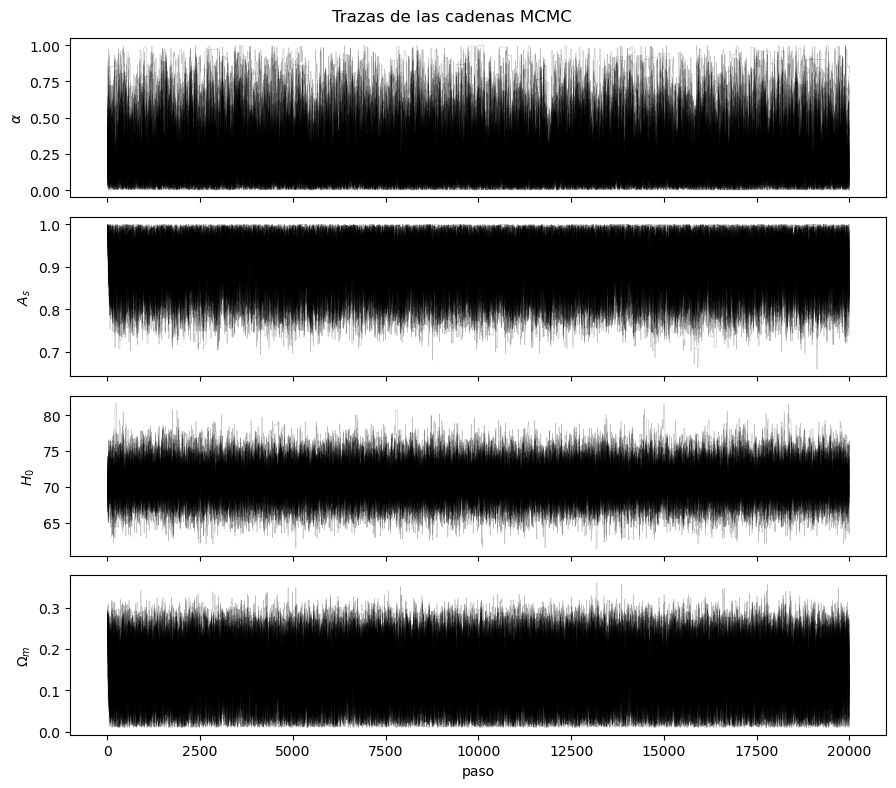

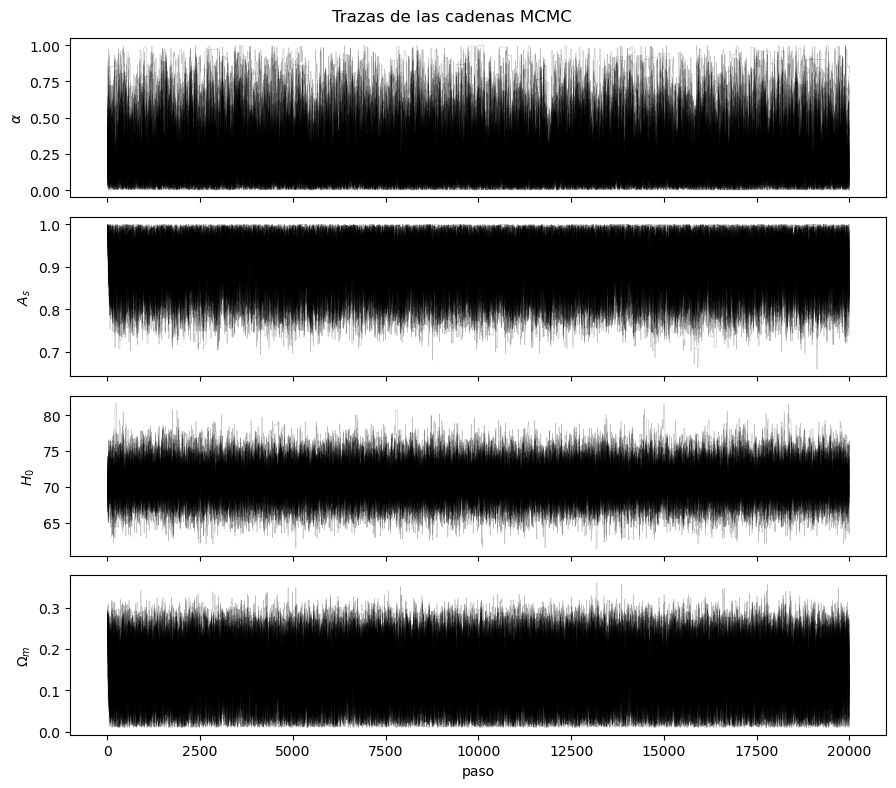

In [17]:
idx = np.random.default_rng(0).choice(len(flat), min(600, len(flat)),
                                      replace=False)
figura_trazas(chain)

In [18]:
def figura_corner(flat, best):
    # smooth=None: alpha y A_s se apilan contra el borde del prior, y el
    # suavizado gaussiano derrama densidad fuera de la region fisica.
    # Los titulos de alpha y A_s NO son intervalos de credibilidad validos.
    fig = corner.corner(flat, labels=LABELS, show_titles=True, title_fmt=".3f",
                        color="royalblue", quantiles=[0.16, 0.5, 0.84],
                        bins=40, smooth=None,
                        range=[(0.0, 1.0), (0.0, 1.0), (20.0, 100.0), (0.01, 0.6)])
    corner.overplot_lines(fig, best, color="crimson", lw=1.1)
    corner.overplot_points(fig, best[None], marker="s", ms=5, color="crimson")
    fig.suptitle("rojo = MAP   (los titulos de alpha y A_s no son intervalos validos)",
                 fontsize=9, y=1.02)
    guardar_figura(fig, "03_corner")
    return fig

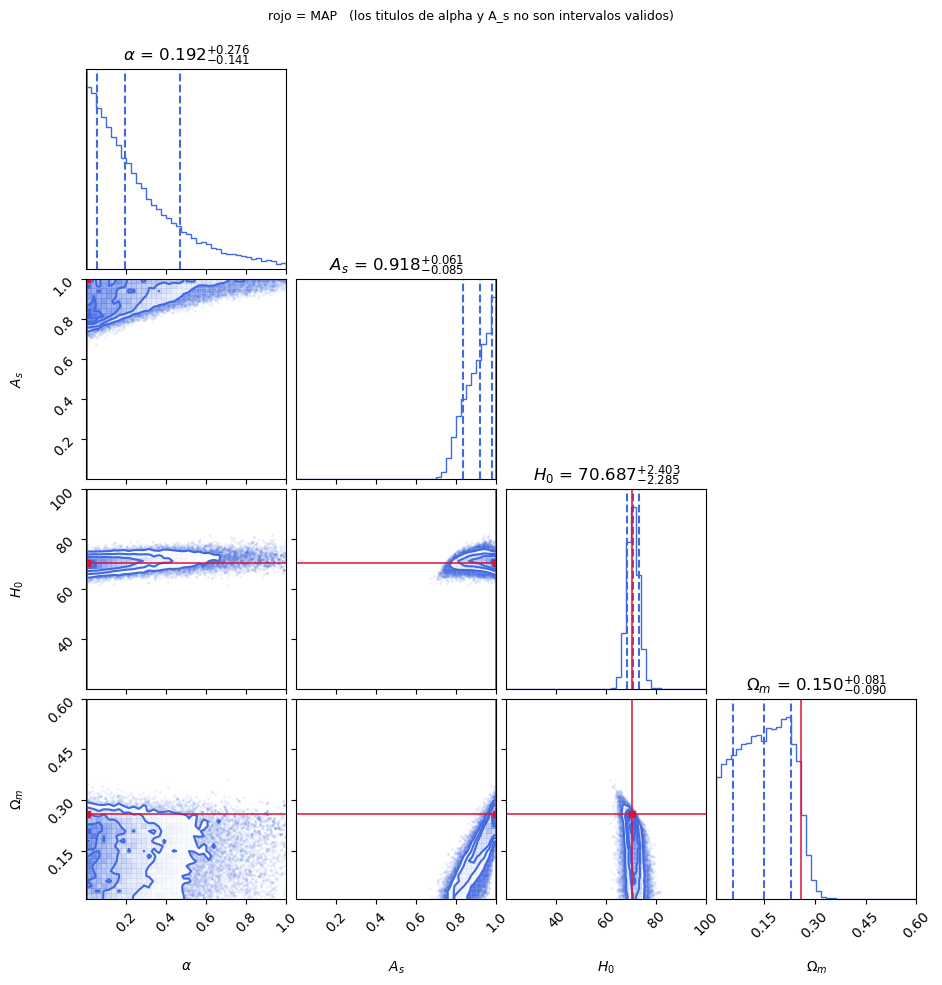

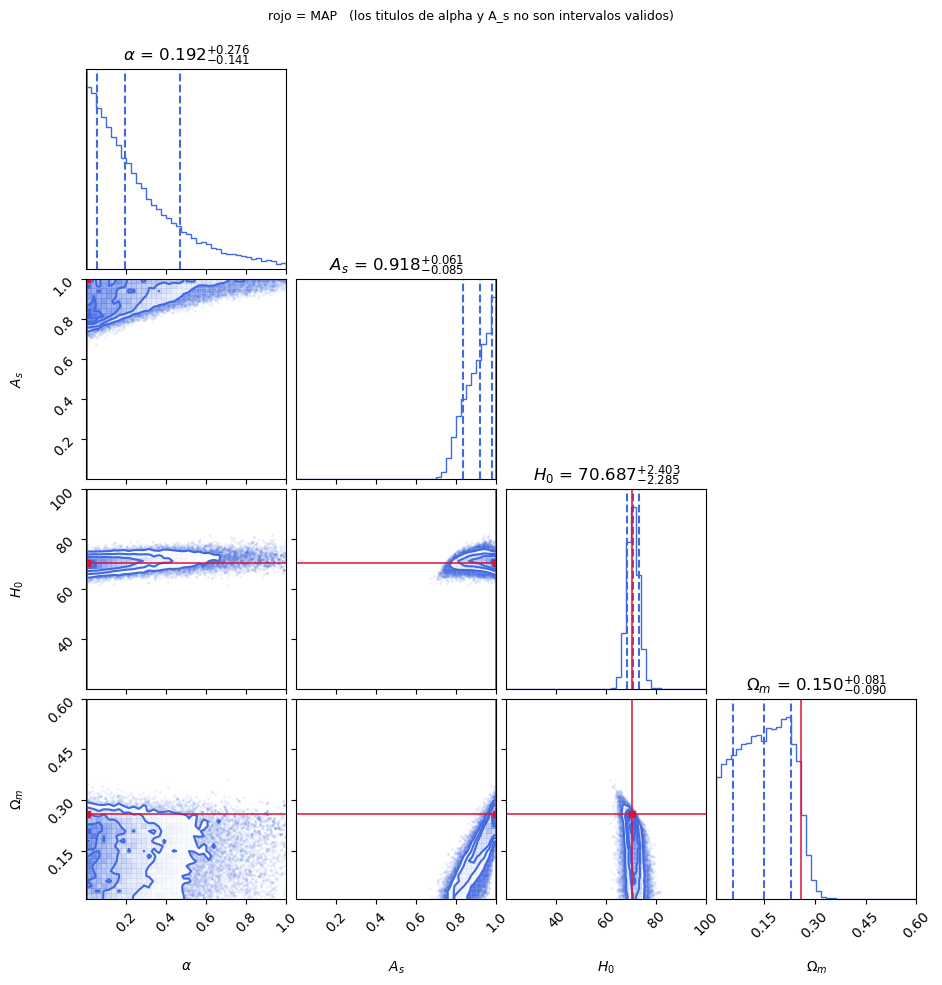

In [19]:
figura_corner(flat, best)

In [20]:
def figura_hz_banda(flat, best, best_lcdm, idx):
    """La banda son los percentiles 16-84 PUNTO A PUNTO: para cada z por
    separado, el 68% de las curvas del posterior cae dentro. NO significa que
    haya un 68% de probabilidad de que la curva verdadera este entera dentro:
    esa probabilidad (banda simultanea) es bastante menor."""
    zg = np.linspace(0, 2.6, 400)
    draws = np.array([H_model(zg, *flat[i]) for i in idx])
    lo, med, hi = np.percentile(draws, [16, 50, 84], axis=0)

    fig = plt.figure(figsize=(9, 6))
    plt.errorbar(Z_HZ, H_OBS, yerr=H_ERR, fmt="o", ms=4, capsize=3,
                 color="C0", ecolor="lightsteelblue", label="Datos $H(z)$")
    plt.fill_between(zg, lo, hi, color="orange", alpha=0.35,
                     label="banda 68% punto a punto")
    plt.plot(zg, med, "r-", lw=2, label="Mediana del posterior")
    plt.plot(zg, H_model(zg, *best), "b-", lw=1.4, label="GCG (modelo ajustado)")
    plt.plot(zg, best_lcdm[0] * np.sqrt(best_lcdm[1] * (1 + zg) ** 3 + 1 - best_lcdm[1]),
             "k--", lw=1.2, label=r"$\Lambda$CDM ")
    plt.xlabel("$z$", fontsize=13)
    plt.ylabel(r"$H(z)\ [\mathrm{km\,s^{-1}\,Mpc^{-1}}]$", fontsize=13)
    plt.title("Gas de Chaplygin generalizado: ajuste de $H(z)$")
    plt.legend()
    plt.grid(alpha=0.3)
    guardar_figura(fig, "04_hz_banda")
    return fig


Resultado

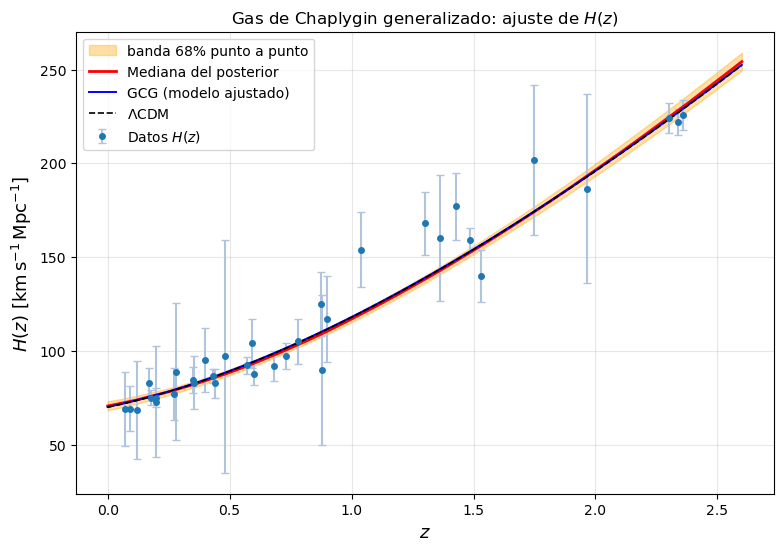

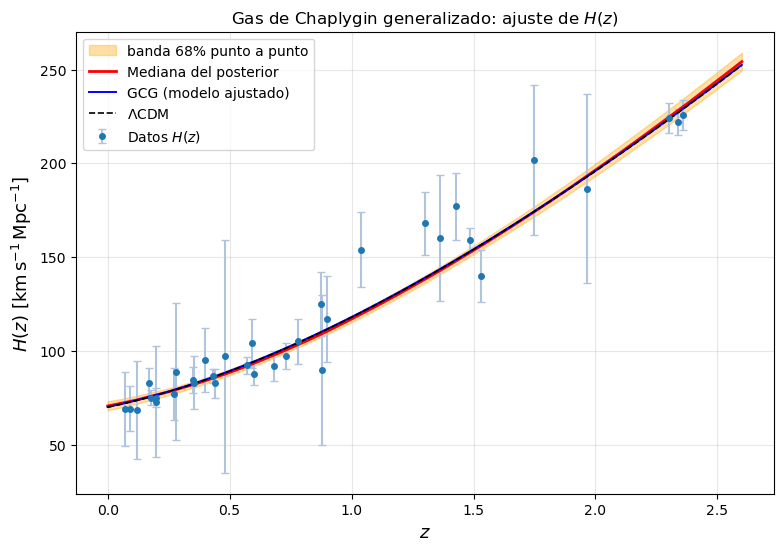

In [21]:
figura_hz_banda(flat, best, best_lcdm, idx)


In [22]:


def figura_contornos(best, chi2_min_gcg, n=50):
    """chi^2 perfilado sobre (H0, Om) en el plano (alpha, A_s).

    A_s llega hasta 0.999: si se corta en 0.99, justo donde cae el minimo, los
    contornos quedan ABIERTOS y el nivel cero se toma demasiado alto. El nivel
    de referencia es el minimo GLOBAL.

    Los contornos quedan abiertos contra A_s = 1, y eso no es un defecto del
    dibujo: el ajuste no cierra una region por arriba porque A_s = 1 (LCDM) ES
    el mejor ajuste. Las etiquetas 68.3% y 95.4% hay que leerlas como regiones
    de EXCLUSION hacia abajo y hacia la derecha.
    """
    titulo("8.4 Regiones de confianza en (alpha, A_s)", nivel=2)
    ag = np.linspace(0.01, 1.0, n)
    bg = np.linspace(0.50, 0.999, n)
    grid = np.zeros((len(bg), len(ag)))

    def nll(p, a, b):
        H0, Om = p
        if not (20 < H0 < 100 and 0.01 < Om < 0.6):
            return 1e6
        c = chi2_total(a, b, H0, Om)
        return c if np.isfinite(c) else 1e6

    for i, b in enumerate(bg):
        for j, a in enumerate(ag):
            r = minimize(nll, x0=[best[2], best[3]], args=(a, b),
                         method="Nelder-Mead",
                         options={"xatol": 1e-4, "fatol": 1e-4, "maxiter": 400})
            grid[i, j] = r.fun

    chi2_ref = min(chi2_min_gcg, float(grid.min()))
    d1 = chi2_dist.ppf(0.6827, 2)     # 2.30
    d2 = chi2_dist.ppf(0.9545, 2)     # 6.18
    print(f"chi2_ref = {chi2_ref:.3f} (minimo global)   niveles: +{d1:.2f}, +{d2:.2f}")
    k = np.unravel_index(np.argmin(grid), grid.shape)
    print(f"minimo de la malla en alpha = {ag[k[1]]:.3f}, A_s = {bg[k[0]]:.3f}"
          f"   (pegado al borde A_s? {'SI' if k[0] in (0, len(bg) - 1) else 'no'})")

    A, B = np.meshgrid(ag, bg)        # A -> eje x (alpha), B -> eje y (A_s)
    fig = plt.figure(figsize=(7.5, 6))
    plt.contourf(A, B, grid, levels=[chi2_ref, chi2_ref + d1, chi2_ref + d2],
                 colors=["#2b5fa8", "#7fa8d8"], alpha=0.85)
    cs = plt.contour(A, B, grid, levels=[chi2_ref + d1, chi2_ref + d2],
                     colors=["navy", "steelblue"], linewidths=1.2)
    plt.clabel(cs, fmt={chi2_ref + d1: "68.3%", chi2_ref + d2: "95.4%"}, fontsize=9)
    plt.plot(ag[k[1]], bg[k[0]], "r*", ms=15, label="mejor ajuste (perfilado)")
    # El articulo obtuvo alpha lejos de cero porque FIJO Omega_m; al dejarlo
    # libre, la degeneracion A_s-Om empuja la solucion hacia alpha->0, A_s->1.
    plt.plot(0.51, 0.73, "kD", ms=7, label=r"paper, $\Omega_m=0.05$ (fijo)")
    plt.plot(0.95, 0.95, "kv", ms=8, label=r"paper, $\Omega_m=0.30$ (fijo)")
    plt.axhline(1.0, color="k", lw=1.0, ls="--")
    plt.text(0.5, 0.996, r"$A_s=1$: $\Lambda$CDM exacto, para cualquier $\alpha$",
             ha="center", va="top", fontsize=8.5)
    plt.xlabel(r"$\alpha$", fontsize=14)
    plt.ylabel(r"$A_s$", fontsize=14)
    plt.title(r"$\chi^2$ perfilado sobre $(H_0,\Omega_m)$ en el plano $(\alpha, A_s)$")
    plt.legend(fontsize=9, loc="lower left")
    guardar_figura(fig, "05_contornos")
    return fig

Resultado


------------------------------------------------------------------------------
8.4 Regiones de confianza en (alpha, A_s)
------------------------------------------------------------------------------
chi2_ref = 17.828 (minimo global)   niveles: +2.30, +6.18
minimo de la malla en alpha = 0.010, A_s = 0.999   (pegado al borde A_s? SI)


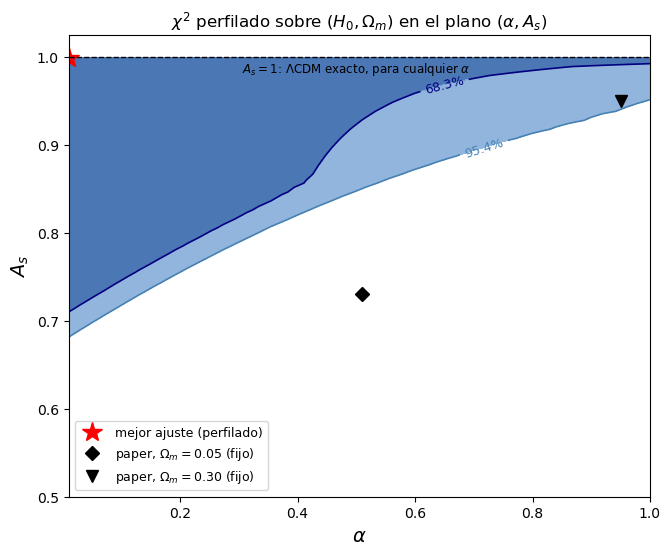

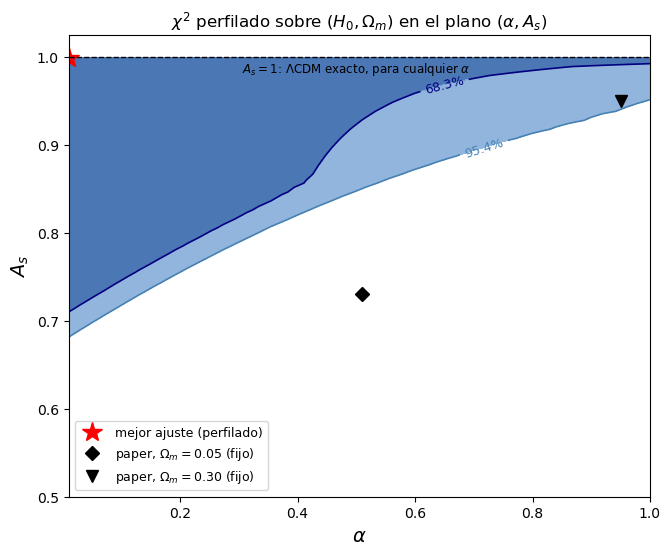

In [23]:
figura_contornos(best, chi2_min)

In [24]:
def figura_q(flat, best, idx):
    zq = np.linspace(0, 2.0, 300)
    q_draws = np.array([deceleration_parameter(zq, flat[i][0], flat[i][1], flat[i][3])
                        for i in idx])
    qlo, qmed, qhi = np.percentile(q_draws, [16, 50, 84], axis=0)

    fig = plt.figure(figsize=(8, 5.5))
    plt.fill_between(zq, qlo, qhi, color="orange", alpha=0.35, label="68% punto a punto")
    plt.plot(zq, qmed, "b-", lw=2, label="$q(z)$ mediana del posterior")
    plt.plot(zq, deceleration_parameter(zq, best[0], best[1], best[3]),
             "r-", lw=1.4, label="$q(z)$ en el MAP")
    plt.axhline(0, color="k", lw=0.8)
    cruces = np.where(np.diff(np.sign(qmed)) != 0)[0]
    if cruces.size:
        plt.axvline(zq[cruces[0]], color="green", ls=":",
                    label=f"$z_t \\approx {zq[cruces[0]]:.2f}$")
    plt.xlabel("$z$", fontsize=13)
    plt.ylabel("$q(z)$", fontsize=13)
    plt.title("Parametro de desaceleracion")
    plt.legend()
    plt.grid(alpha=0.3)
    guardar_figura(fig, "06_q")
    return fig

Resultado

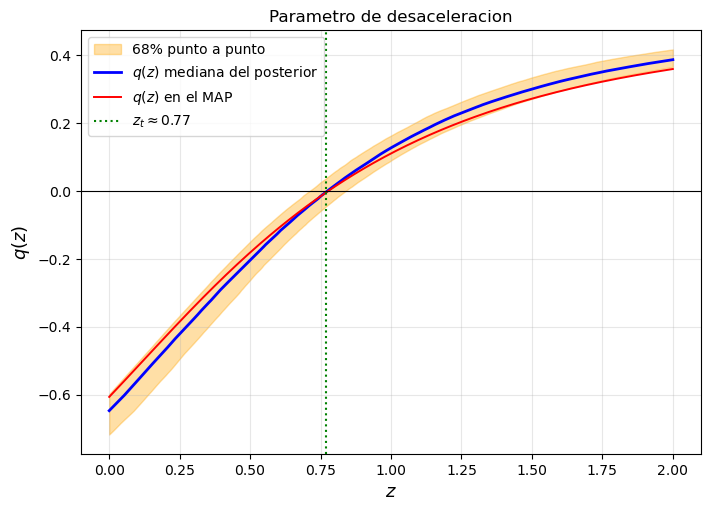

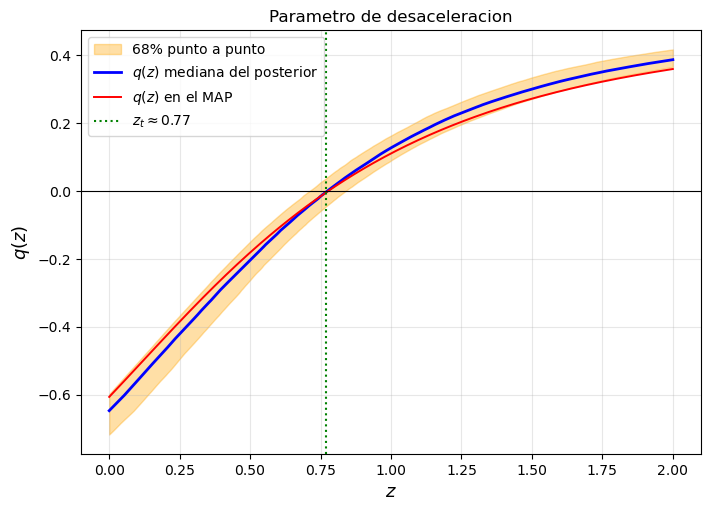

In [25]:
figura_q(flat, best, idx)

In [26]:
def figura_distancia_luminosa(best):
    zs = np.linspace(0.001, 3.0, 400)
    fig = plt.figure(figsize=(8, 5.5))
    plt.plot(zs, luminosity_distance(zs, *best), "b-", lw=2, label="GCG (Modelo ajustado)")
    plt.xlabel("$z$", fontsize=13)
    plt.ylabel(r"$d_L(z)\ [\mathrm{Mpc}]$", fontsize=13)
    plt.title("Distancia luminosa del gas de Chaplygin generalizado")
    plt.legend()
    plt.grid(alpha=0.3)
    guardar_figura(fig, "07_distancia_luminosa")
    return fig


Resultado

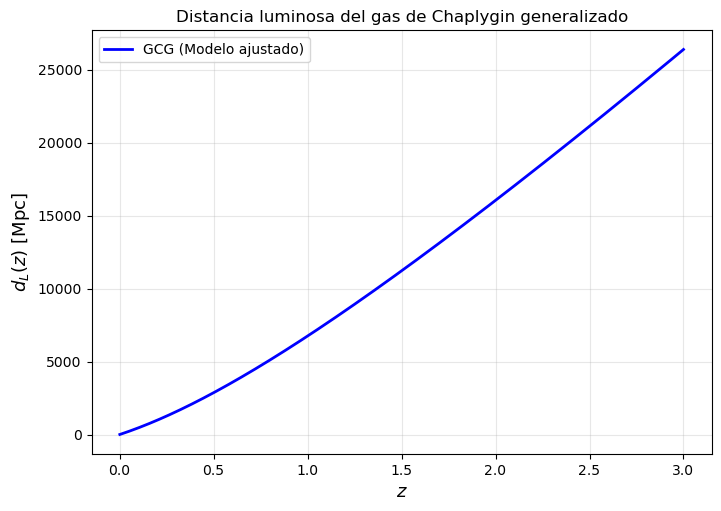

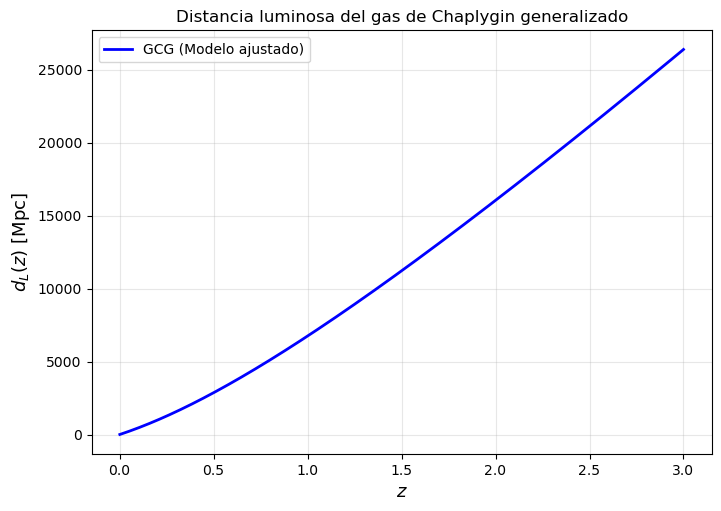

In [27]:
figura_distancia_luminosa(best)

In [28]:
def figura_hubble_pantheon(best):
    """Los datos se grafican en el marco del CMB: m_B - M - dmu_hel, con
    dmu_hel = 5 log10((1+z_hel)/(1+z_cmb)). Asi los dos paneles usan la misma
    convencion que la curva del modelo, que va con (1+z_cmb)."""
    if PANTHEON is None:
        print("\nsin figura del diagrama de Hubble: no hay datos de "
              "Pantheon cargados. Es la unica figura que los "
              "necesita.\n   Pon la carpeta de los datos en "
              "pantheon=... en la celda de configuracion\n   y "
              "vuelve a ejecutar desde ahi.")
        return None
    M_best = PANTHEON.best_M(*best)
    print(f"\nmagnitud absoluta ajustada: M = {M_best:.4f}")

    dmu_hel = 5.0 * np.log10((1.0 + PANTHEON.zhel) / (1.0 + PANTHEON.zcmb))
    mu_dat = PANTHEON.mb - M_best - dmu_hel
    zs = np.logspace(np.log10(PANTHEON.zcmb.min()),
                     np.log10(PANTHEON.zcmb.max()), 400)

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 8), sharex=True,
                                   gridspec_kw={"height_ratios": [3, 1]})
    ax1.errorbar(PANTHEON.zcmb, mu_dat, yerr=PANTHEON.dmb, fmt="o", ms=2.5,
                 alpha=0.5, color="C0", ecolor="lightsteelblue",
                 label="Pantheon (marco CMB)")
    ax1.plot(zs, distance_modulus(zs, *best), "r-", lw=2, label="GCG (MAP)")
    ax1.set_ylabel(r"$\mu(z)$", fontsize=13)
    ax1.set_title("Diagrama de Hubble - Pantheon")
    ax1.legend()
    ax1.grid(alpha=0.3)

    ax2.errorbar(PANTHEON.zcmb, mu_dat - distance_modulus(PANTHEON.zcmb, *best),
                 yerr=PANTHEON.dmb, fmt="o", ms=2.5, alpha=0.5, color="C0",
                 ecolor="lightsteelblue")
    ax2.axhline(0, color="r", lw=1.5)
    ax2.set_xscale("log")
    ax2.set_xlabel("$z$", fontsize=13)
    ax2.set_ylabel("residuos")
    ax2.grid(alpha=0.3)
    fig.tight_layout()
    guardar_figura(fig, "08_hubble_pantheon")
    return fig

Resultado

In [29]:
figura_hubble_pantheon(best)

## 9. El sistema dinamico del articulo (sus secciones II-IV)
El articulo usa 8 pi G / 3 = 1, asi que la primera
ecuacion de Friedmann es:

$$ 3H^2 = \rho - 3k/a^2$$

 y la de Raychaudhuri es:

$$a_dd/a = -(\rho + 3p)/6$$

Notamos que no hay termino de materia, eñ gas es
todo el contenido.

Con $p = -A/\rho^\alpha$, la conservacion da $d \rho/dt = -3H(\rho^{(1+a)} - A)/\rho^a$,
singular en $\rho \to 0$. 

Ademas el articulo reparametriza el tiempo como: $d \tau = dt/\rho^a$, y
obtiene un sistema polinomico, su ec. (20):

$$\frac{dH}{d\tau} = -H^2\rho^\alpha - \frac{\rho^{1+\alpha}-3A}{6}\;\equiv\; P(H,\rho), \qquad\frac{d\rho}{d\tau} = -3H\left(\rho^{1+\alpha}-A\right)\;\equiv\; Q(H,\rho)$$

Como $\rho^a > 0$, el reescalado no cambia la orientacion del tiempo ni el
caracter de los puntos criticos: solo la parametrizacion de las orbitas.

La condicion de energia debil se satisface para
$\rho >= \rho_{min} = A^{(1/(1+alpha))}$, que es tambien el valor asintotico de $\rho$.

In [30]:
def PQ(H, rho, alpha, A):
    """Lado derecho del sistema (20): dH/dtau = P, drho/dtau = Q."""
    ra = rho ** alpha
    r1a = rho ** (1.0 + alpha)
    return (-H ** 2 * ra - (r1a - 3.0 * A) / 6.0,
            -3.0 * H * (r1a - A))


def critical_points(alpha, A):
    """Puntos criticos del sistema (20): (nombre, H0, rho0).

    1) estatico   : H=0, rho=(3A)^(1/(1+a))                  -> Einstein
    2) no estatico: H=+-A^(1/(2(1+a)))/sqrt(3), rho=A^(1/(1+a)) -> de Sitter

    OJO: el articulo escribe "rho_0 = A" para el punto no estatico; es una
    abreviatura de rho_0 = A^(1/(1+alpha)), que es el rho_min de la condicion
    de energia debil. Con "rho_0 = A" literal el punto no anula Q.
    """
    rho_s = (3.0 * A) ** (1.0 / (1.0 + alpha))
    rho_ns = A ** (1.0 / (1.0 + alpha))
    H_ns = A ** (1.0 / (2.0 * (1.0 + alpha))) / np.sqrt(3.0)
    return [("estatico (Einstein)", 0.0, rho_s),
            ("de Sitter (futuro)", +H_ns, rho_ns),
            ("de Sitter (pasado)", -H_ns, rho_ns)]


def jacobian(H, rho, alpha, A):
    """Matriz de linealizacion del sistema (20), analitica."""
    ra = rho ** alpha
    r1a = rho ** (1.0 + alpha)
    return np.array([
        [-2.0 * H * ra,
         -alpha * H ** 2 * rho ** (alpha - 1.0) - (1.0 + alpha) * ra / 6.0],
        [-3.0 * (r1a - A),
         -3.0 * H * (1.0 + alpha) * ra],
    ])


def jacobian_fd(H, rho, alpha, A, h=1e-6):
    """La misma matriz por diferencias centradas, para validar la analitica."""
    J = np.empty((2, 2))
    for j, (dH, dr) in enumerate([(h, 0.0), (0.0, h)]):
        Pp, Qp = PQ(H + dH, rho + dr, alpha, A)
        Pm, Qm = PQ(H - dH, rho - dr, alpha, A)
        J[0, j] = (Pp - Pm) / (2 * h)
        J[1, j] = (Qp - Qm) / (2 * h)
    return J


def classify(lam):
    """Clasifica un punto critico no degenerado por sus autovalores."""
    re, im = np.real(lam), np.imag(lam)
    if np.any(np.abs(re) < 1e-12):
        return "degenerado / no hiperbolico"
    if np.any(np.abs(im) > 1e-12):
        return "foco estable" if np.all(re < 0) else "foco inestable"
    if re[0] * re[1] < 0:
        return "SILLA"
    return "nodo estable" if np.all(re < 0) else "nodo inestable"


def first_integral(H, rho, alpha, A):
    """I(H,rho) = sgn(u)|u|^(3(1+a)/2) / (rho^(1+a) - A),  con u = rho - 3H^2.

    Es la ec. (19) del articulo reescrita como cantidad conservada: vale
    (3k)^(3(1+a)/2)/B sobre cada trayectoria. Se comprueba derivando: con
    w = rho^(1+a) - A se tiene du/dtau = -2 H rho^a u y
    dw/dtau = -3(1+a) H rho^a w, luego d ln|I| / dtau = 0.

    El signo de I es el de la curvatura: I = 0 es el modelo plano k = 0 (la
    parabola rho = 3H^2), I > 0 es k = +1 e I < 0 es k = -1.
    """
    u = rho - 3.0 * H ** 2
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.sign(u) * np.abs(u) ** (1.5 * (1.0 + alpha)) / (rho ** (1.0 + alpha) - A)


def trajectory(H0, rho0, alpha, A, tau_max=8.0, backward=False,
               box=(3.0, 8.0), rho_floor=1e-6):
    """Integra el sistema (20) desde (H0, rho0), hacia delante o hacia atras."""
    s = -1.0 if backward else 1.0

    def rhs(_t, y):
        P, Q = PQ(y[0], max(y[1], rho_floor), alpha, A)
        return [s * P, s * Q]

    def escapa(_t, y):
        return min(box[0] - abs(y[0]), box[1] - y[1], y[1] - rho_floor)

    escapa.terminal = True
    escapa.direction = -1
    sol = solve_ivp(rhs, (0.0, tau_max), [H0, rho0], events=escapa,
                    rtol=1e-9, atol=1e-11, max_step=0.01)
    return sol.y[0], sol.y[1]


def V_pot(a, alpha, A, B, k=0.0):
    """Potencial V(a) = -rho(a) a^2 / 6 + k/2, en el nivel de energia cero.

    De la ec. (23)-(28) del articulo: a_dd = -dV/da, y la constriccion
    hamiltoniana a_dot^2/2 + V(a) = 0 coincide con Friedmann.
    """
    rho = (A + B / a ** (3.0 * (1.0 + alpha))) ** (1.0 / (1.0 + alpha))
    return -rho * a ** 2 / 6.0 + k / 2.0


def analisis_dinamico(cfg: Config, alpha_map=None):
    """Comprobaciones del sistema (20), puntos criticos y autovalores."""
    alpha, A = cfg.alpha_din, cfg.A_din
    titulo("9. El sistema dinamico del articulo")

    # --- el sistema (20) reproduce Friedmann + conservacion ---------------
    a0, B, da = 0.8, cfg.B_din, 1e-6

    def rho_of_a(x):
        return (A + B / x ** (3.0 * (1.0 + alpha))) ** (1.0 / (1.0 + alpha))

    def H_of_a(x):          # modelo plano: 3H^2 = rho
        return np.sqrt(rho_of_a(x) / 3.0)

    rho, H = rho_of_a(a0), H_of_a(a0)
    adot = a0 * H
    drho_dt = (rho_of_a(a0 + da) - rho_of_a(a0 - da)) / (2 * da) * adot
    dH_dt = (H_of_a(a0 + da) - H_of_a(a0 - da)) / (2 * da) * adot
    P, Q = PQ(H, rho, alpha, A)
    print("comprobacion 1 -- el sistema (20) reproduce Friedmann + conservacion")
    print(f"  dH/dtau   : numerico {dH_dt * rho ** alpha:+.10f}   P(H,rho) {P:+.10f}")
    print(f"  drho/dtau : numerico {drho_dt * rho ** alpha:+.10f}   Q(H,rho) {Q:+.10f}")

    # --- la parabola k=0 es invariante ------------------------------------
    Hs = np.linspace(-1.5, 1.5, 7)
    du = np.array([PQ(h, 3 * h ** 2, alpha, A)[1] - 6 * h * PQ(h, 3 * h ** 2, alpha, A)[0]
                   for h in Hs])
    print("\ncomprobacion 2 -- la parabola rho = 3H^2 (k=0) es invariante")
    print(f"  max |d(rho-3H^2)/dtau| sobre la parabola = {np.max(np.abs(du)):.2e}")
    h_, r_ = 0.7, 2.3
    P2, Q2 = PQ(h_, r_, alpha, A)
    print(f"  identidad du/dtau = -2 H rho^a u :  {Q2 - 6 * h_ * P2:+.10f}  vs  "
          f"{-2 * h_ * r_ ** alpha * (r_ - 3 * h_ ** 2):+.10f}")

    # --- puntos criticos y autovalores ------------------------------------
    casos = [(alpha, A, "Fig. 2a del paper"), (0.51, 1.0, "mejor ajuste SNIa del paper")]
    if alpha_map is not None:
        casos.append((float(alpha_map), 1.0, "alpha del MAP de este ajuste"))

    for al, Ai, etiqueta in casos:
        print(f"\n{'=' * 78}\nalpha = {al:.4f},  A = {Ai}   ({etiqueta})\n{'=' * 78}")
        for nombre, H0, rho0 in critical_points(al, Ai):
            P0, Q0 = PQ(H0, rho0, al, Ai)
            J = jacobian(H0, rho0, al, Ai)
            Jfd = jacobian_fd(H0, rho0, al, Ai)
            lam = np.linalg.eigvals(J)
            lam = lam[np.argsort(-np.real(lam))]

            # Autovalores en forma cerrada. Para el punto no estatico,
            # rho_0^(1+a) = A anula dQ/dH, la matriz queda triangular y salen
            # exactos: lambda_1 = -2 H0 rho0^a, lambda_2 = -3(1+a) H0 rho0^a.
            ra = rho0 ** al
            if H0 == 0.0:
                cerrada = np.array([+1.0, -1.0]) * np.sqrt(Ai * (1.0 + al) * ra)
            else:
                cerrada = np.array([-2.0 * H0 * ra, -3.0 * (1.0 + al) * H0 * ra])
            cerrada = cerrada[np.argsort(-np.real(cerrada))]

            print(f"\n  {nombre}:  H0 = {H0:+.6f}   rho0 = {rho0:.6f}")
            print(f"    residuo (P,Q)        = ({P0:+.2e}, {Q0:+.2e})   <- debe ser ~0")
            print(f"    |J_analitica - J_df| = {np.max(np.abs(J - Jfd)):.2e}")
            print(f"    Tr = {np.trace(J):+.6f}   det = {np.linalg.det(J):+.6f}"
                  f"   Delta = {np.trace(J) ** 2 - 4 * np.linalg.det(J):+.6f}")
            print(f"    autovalores          = {np.round(lam, 6)}")
            print(f"    forma cerrada        = {np.round(cerrada, 6)}"
                  f"   (dif {np.max(np.abs(lam - cerrada)):.2e})")
            print(f"    tipo                 = {classify(lam)}")

    # --- conservacion del primer integral ---------------------------------
    print(f"\n{'=' * 78}\nconservacion del primer integral (ec. 19)\n{'=' * 78}")
    print("Con u = rho - 3H^2 y w = rho^(1+a) - A, I = sgn(u)|u|^(3(1+a)/2)/w.")
    print("Cerca del atractor de Sitter u y w tienden a cero a la vez, de modo que")
    print("I es un cociente 0/0 mal condicionado: se mide donde |w| > 1e-3.\n")
    print(f"{'inicio (H, rho)':<22}{'k':>3}{'I inicial':>13}{'desv. abs.':>13}{'desv. rel.':>13}")
    print("-" * 64)
    for H0, rho0 in [(0.60, 3.00), (-0.60, 3.00), (0.90, 2.00),
                     (0.20, 1.80), (0.76, 3 * 0.76 ** 2)]:
        Ht, rt = trajectory(H0, rho0, alpha, A)
        I = first_integral(Ht, rt, alpha, A)
        I0 = first_integral(np.array([H0]), np.array([rho0]), alpha, A)[0]
        ok = np.abs(rt ** (1.0 + alpha) - A) > 1e-3
        k = 0 if abs(I0) < 1e-12 else (1 if I0 > 0 else -1)
        dabs = np.max(np.abs(I[ok] - I0)) if ok.any() else np.nan
        drel = f"{dabs / abs(I0):13.2e}" if abs(I0) > 1e-12 else f"{'--':>13}"
        print(f"({H0:+.2f}, {rho0:.4f}){'':<6}{k:>3}{I0:>13.6f}{dabs:>13.2e}{drel}")
    print("\n(la ultima fila arranca exactamente sobre la parabola: k = 0, I = 0)")

In [31]:
analisis_dinamico(CFG, alpha_map)


9. El sistema dinamico del articulo
comprobacion 1 -- el sistema (20) reproduce Friedmann + conservacion
  dH/dtau   : numerico -3.2424926759   P(H,rho) -3.2424926758
  drho/dtau : numerico -18.5787874185   Q(H,rho) -18.5787874178

comprobacion 2 -- la parabola rho = 3H^2 (k=0) es invariante
  max |d(rho-3H^2)/dtau| sobre la parabola = 0.00e+00
  identidad du/dtau = -2 H rho^a u :  -2.6726000000  vs  -2.6726000000

alpha = 1.0000,  A = 1.0   (Fig. 2a del paper)

  estatico (Einstein):  H0 = +0.000000   rho0 = 1.732051
    residuo (P,Q)        = (+7.40e-17, -0.00e+00)   <- debe ser ~0
    |J_analitica - J_df| = 4.10e-11
    Tr = +0.000000   det = -3.464102   Delta = +13.856406
    autovalores          = [ 1.86121 -1.86121]
    forma cerrada        = [ 1.86121 -1.86121]   (dif 4.44e-16)
    tipo                 = SILLA

  de Sitter (futuro):  H0 = +0.577350   rho0 = 1.000000
    residuo (P,Q)        = (-1.11e-16, -0.00e+00)   <- debe ser ~0
    |J_analitica - J_df| = 2.90e-11
    Tr = -

In [32]:
def figura_retrato_fase(cfg: Config):
    """Retrato de fase del sistema (20). Reproduce la Fig. 1a/2a del articulo.

    Elementos: campo vectorial; parabola rho = 3H^2 (k=0), variedad invariante
    que separa cerrados de abiertos; linea rho_min (frontera de la WEC, con los
    dos puntos de de Sitter encima); y linea rho = (3A)^(1/(1+a)), que pasa por
    el punto estatico y es la frontera de aceleracion, porque a_dd > 0 <=>
    rho + 3p < 0 <=> rho^(1+a) < 3A.

    El panel derecho usa E = sqrt(rho), el cambio de la Fig. 3 del articulo.
    """
    alpha, A = cfg.alpha_din, cfg.A_din
    rho_min = A ** (1.0 / (1.0 + alpha))
    rho_stat = (3.0 * A) ** (1.0 / (1.0 + alpha))
    RHO_MAX = 4.0

    fig, axes = plt.subplots(1, 2, figsize=(13.5, 6))
    for ax, usar_E in zip(axes, [False, True]):
        # streamplot exige malla UNIFORME en los dos ejes, asi que en el panel
        # (H, E) la malla se construye directamente en E y no como sqrt de una
        # malla uniforme en rho (que no queda equiespaciada).
        Hg = np.linspace(-1.5, 1.5, 420)
        if usar_E:                     # E = sqrt(rho)  =>  dE/dtau = Q/(2E)
            Yg = np.linspace(1e-2, np.sqrt(RHO_MAX), 420)
            HH, YY = np.meshgrid(Hg, Yg)
            P, Q = PQ(HH, YY ** 2, alpha, A)
            V = Q / (2.0 * YY)
        else:
            Yg = np.linspace(1e-3, RHO_MAX, 420)
            HH, YY = np.meshgrid(Hg, Yg)
            P, V = PQ(HH, YY, alpha, A)

        ax.streamplot(Hg, Yg, P, V, color="0.65", density=1.5,
                      linewidth=0.7, arrowsize=0.9)
        f = np.sqrt if usar_E else (lambda x: x)

        ax.axhspan(f(1e-3), f(rho_min), color="0.85", alpha=0.6, zorder=0)
        ax.axhspan(f(rho_min), f(rho_stat), color="gold", alpha=0.18, zorder=0)
        ax.axhline(f(rho_min), color="k", lw=1.0, ls="-")
        ax.axhline(f(rho_stat), color="darkgoldenrod", lw=1.0, ls="-.")

        Hp = np.linspace(-1.5, 1.5, 400)
        ax.plot(Hp, f(3 * Hp ** 2), "b-", lw=1.8, zorder=3)

        for H0, r0 in [(0.35, 3.60), (-0.35, 3.60), (0.95, 3.60), (-0.95, 3.60),
                       (0.30, 1.35), (-0.30, 1.35), (1.10, 1.60), (-1.10, 1.60)]:
            for atras in (False, True):
                Ht, rt = trajectory(H0, r0, alpha, A, backward=atras)
                ax.plot(Ht, f(rt), "-", color="crimson", lw=1.1, alpha=0.85, zorder=2)

        # El tipo se decide por el signo de la parte real de los autovalores,
        # no por el texto de classify(): "inestable" contiene "estable" como
        # subcadena y pintaria los dos nodos del mismo color.
        for nombre, H0, r0 in critical_points(alpha, A):
            re = np.real(np.linalg.eigvals(jacobian(H0, r0, alpha, A)))
            if re[0] * re[1] < 0:
                est = dict(marker="s", color="k")
            elif np.all(re < 0):
                est = dict(marker="o", color="limegreen")
            else:
                est = dict(marker="o", color="white")
            ax.plot([H0], [f(r0)], ms=11, mec="k", mew=1.4, zorder=5, ls="none", **est)

        ax.set_xlabel("$H$", fontsize=13)
        ax.set_ylabel("$E=\\sqrt{\\rho}$" if usar_E else r"$\rho$", fontsize=13)
        ax.set_xlim(-1.5, 1.5)
        ax.set_ylim(Yg[0], Yg[-1])
        ax.set_title(("plano $(H, E)$ - Fig. 3 del paper" if usar_E
                      else "plano $(H, \\rho)$ - Fig. 1a/2a del paper"), fontsize=11)

    fig.suptitle(f"Retrato de fase del gas de Chaplygin generalizado "
                 f"($A={A:g}$, $\\alpha={alpha:g}$)", fontsize=13)
    fig.tight_layout(rect=(0, 0.11, 1, 0.97))
    fig.legend(handles=[
        Line2D([], [], color="b", lw=1.8, label=r"$\rho=3H^2$  ($k=0$)"),
        Line2D([], [], color="crimson", lw=1.1, label="trayectorias"),
        Line2D([], [], color="k", lw=1.0, label=r"$\rho_{\min}=A^{1/(1+\alpha)}$  (WEC)"),
        Line2D([], [], color="darkgoldenrod", lw=1.0, ls="-.",
               label=r"$\rho=(3A)^{1/(1+\alpha)}$"),
        Patch(facecolor="gold", alpha=0.3, label="acelera (region fisica)"),
        Line2D([], [], ls="none", marker="s", color="k", mec="k", ms=9,
               label="silla (Einstein estatico)"),
        Line2D([], [], ls="none", marker="o", color="limegreen", mec="k", ms=9,
               label="nodo estable (deS futuro)"),
        Line2D([], [], ls="none", marker="o", color="white", mec="k", ms=9,
               label="nodo inestable (deS pasado)"),
        Patch(facecolor="0.85", alpha=0.8, label="viola la WEC"),
    ], fontsize=8.5, loc="lower center", ncol=5, framealpha=0.95)
    guardar_figura(fig, "09_retrato_fase")

    print("\nLectura del retrato:")
    print("  - los dos nodos de de Sitter estan sobre rho = rho_min; el atractor")
    print(f"    global del modelo en expansion es de Sitter con H -> "
          f"{A ** (1 / (2 * (1 + alpha))) / np.sqrt(3):.6f}")
    print("  - el punto estatico es una silla: el universo de Einstein es inestable")
    print("  - no hay orbitas que conecten sillas ni ciclos limite, y todos los")
    print("    puntos son hiperbolicos => estructuralmente estable (Peixoto)")
    return fig



Resultados


Lectura del retrato:
  - los dos nodos de de Sitter estan sobre rho = rho_min; el atractor
    global del modelo en expansion es de Sitter con H -> 0.577350
  - el punto estatico es una silla: el universo de Einstein es inestable
  - no hay orbitas que conecten sillas ni ciclos limite, y todos los
    puntos son hiperbolicos => estructuralmente estable (Peixoto)


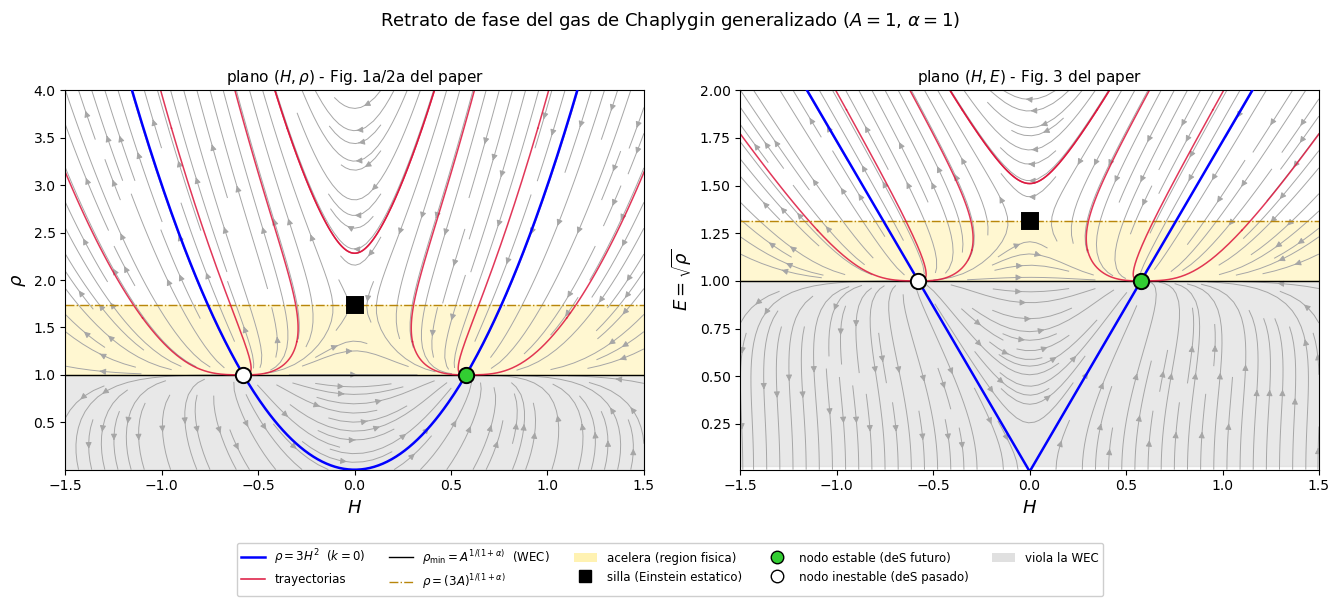

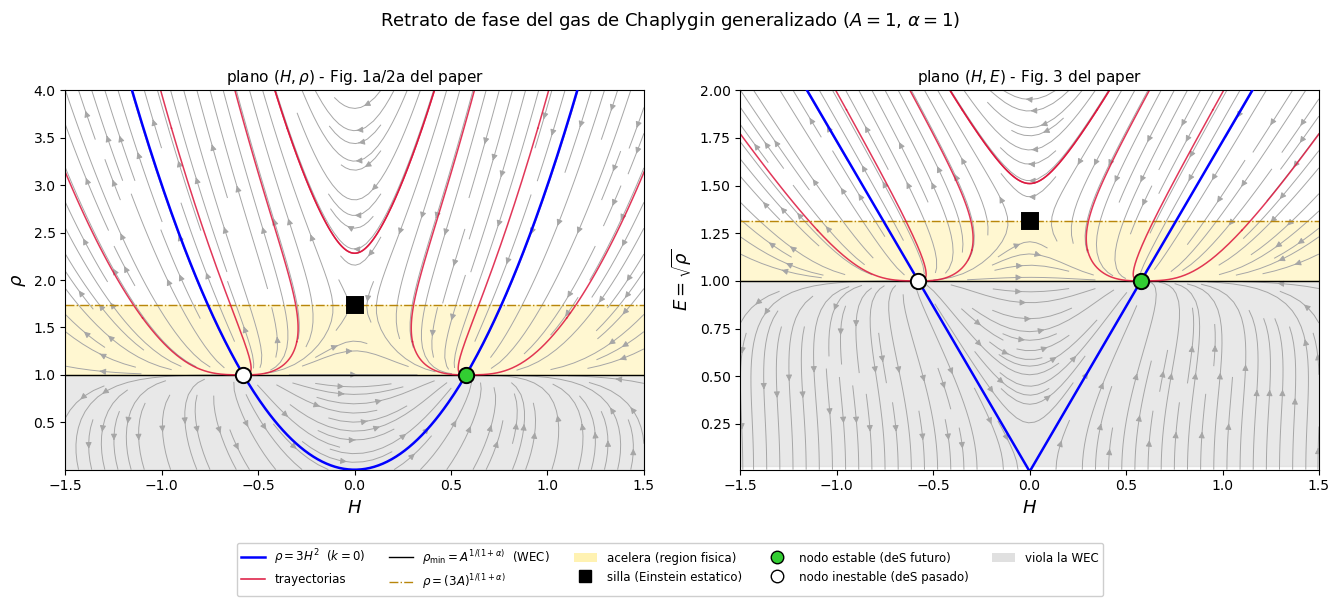

In [33]:
figura_retrato_fase(CFG)

In [34]:
def figura_hamiltoniana(cfg: Config):
    """Formulacion hamiltoniana (seccion IV del articulo) y sus tres resultados."""
    alpha, A, B = cfg.alpha_din, cfg.A_din, cfg.B_din
    titulo("9.4 Formulacion hamiltoniana", nivel=2)

    a_cr = (B / (2.0 * A)) ** (1.0 / (3.0 * (1.0 + alpha)))
    A_s = A / (A + B)
    print(f"alpha = {alpha:g}, A = {A:g}, B = {B:g}   ->   A_s = A/(A+B) = {A_s:.6f}")
    print(f"\n1) aceleracion:  a_cr = (B/2A)^(1/(3(1+alpha))) = {a_cr:.6f}")
    print(f"   z_t equivalente = 1/a_cr - 1 = {1.0 / a_cr - 1.0:.6f}")
    print(f"   formula de la parte 3 [2As/(1-As)]^(1/(3(1+a))) - 1 = "
          f"{(2 * A_s / (1 - A_s)) ** (1 / (3 * (1 + alpha))) - 1:.6f}")

    ag, h = np.linspace(0.05, 3.0, 20000), 1e-6
    addot = -(V_pot(ag + h, alpha, A, B) - V_pot(ag - h, alpha, A, B)) / (2 * h)
    cruce = ag[np.where(np.diff(np.sign(addot)) != 0)[0][0]]
    print(f"   cruce numerico de a_ddot = 0 en a = {cruce:.6f}"
          f"   (dif {abs(cruce - a_cr):.1e})")

    # V'' con paso mas grande que la primera derivada: dividir por h^2 amplifica
    # el error de redondeo.
    h2 = 1e-4
    V2 = (V_pot(ag + h2, alpha, A, B) - 2 * V_pot(ag, alpha, A, B)
          + V_pot(ag - h2, alpha, A, B)) / h2 ** 2
    veredicto = "siempre < 0: solo sillas" if V2.max() < 0 else "ATENCION: hay V'' > 0"
    print(f"\n2) V''(a):  maximo sobre a en [0.05, 3] = {V2.max():+.6f}   -> {veredicto}")
    print("   (en un sistema mecanico natural los puntos criticos solo pueden ser")
    print("    centros (V''>0) o sillas (V''<0); al no haber centros, el modelo es")
    print("    estructuralmente estable)")

    print("\n3) limite a -> 0 (problema del horizonte):")
    for a0 in (1e-1, 1e-2, 1e-3, 1e-4):
        V = V_pot(a0, alpha, A, B)
        print(f"   a = {a0:7.0e}:  V = {V:+12.2f}   a_dot = sqrt(-2V) = "
              f"{np.sqrt(-2 * V):10.2f}   a_dot*sqrt(a) = {np.sqrt(-2 * V) * np.sqrt(a0):.6f}")
    print("   a_dot ~ a^(-1/2) diverge  =>  NO resuelve el problema del horizonte")
    print("   (con a ~ t^(2/3), la distancia al horizonte va como t^(1/3): converge)")

    agp = np.linspace(0.02, 3.0, 2000)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
    for k, c, ls in [(-1.0, "C0", "--"), (0.0, "k", "-"), (1.0, "C3", ":")]:
        ax1.plot(agp, V_pot(agp, alpha, A, B, k), ls, color=c, lw=1.8,
                 label=f"$k={k:+.0f}$")
    ax1.axhline(0, color="0.6", lw=0.8)
    ax1.axvline(a_cr, color="darkgoldenrod", ls="-.", lw=1.2,
                label=f"$a_{{\\rm cr}}={a_cr:.3f}$")
    ax1.set_xlabel("$a$", fontsize=13)
    ax1.set_ylabel("$V(a)$", fontsize=13)
    ax1.set_ylim(-2.5, 1.0)
    ax1.set_title(r"Potencial: el dominio admisible es $D=\{a: V(a)\leq 0\}$", fontsize=11)
    ax1.legend(fontsize=9)
    ax1.grid(alpha=0.3)

    ax2.plot(agp, -(V_pot(agp + 1e-6, alpha, A, B) - V_pot(agp - 1e-6, alpha, A, B)) / 2e-6,
             "b-", lw=1.8, label=r"$\ddot a = -\partial V/\partial a$")
    ax2.axhline(0, color="k", lw=0.8)
    ax2.axvline(a_cr, color="darkgoldenrod", ls="-.", lw=1.2, label=r"$a_{\rm cr}$")
    ax2.fill_between(agp, 0, 1, where=(agp > a_cr), transform=ax2.get_xaxis_transform(),
                     color="gold", alpha=0.18)
    ax2.set_xlabel("$a$", fontsize=13)
    ax2.set_ylabel(r"$\ddot a$", fontsize=13)
    ax2.set_ylim(-0.6, 1.2)
    ax2.set_title(r"Aceleracion para $a>a_{\rm cr}$ (banda dorada)", fontsize=11)
    ax2.legend(fontsize=9)
    ax2.grid(alpha=0.3)
    fig.tight_layout()
    guardar_figura(fig, "10_potencial")
    return fig


------------------------------------------------------------------------------
9.4 Formulacion hamiltoniana
------------------------------------------------------------------------------
alpha = 1, A = 1, B = 1.7   ->   A_s = A/(A+B) = 0.370370

1) aceleracion:  a_cr = (B/2A)^(1/(3(1+alpha))) = 0.973277
   z_t equivalente = 1/a_cr - 1 = 0.027457
   formula de la parte 3 [2As/(1-As)]^(1/(3(1+a))) - 1 = 0.027457
   cruce numerico de a_ddot = 0 en a = 0.973249   (dif 2.8e-05)

2) V''(a):  maximo sobre a en [0.05, 3] = -0.337207   -> siempre < 0: solo sillas
   (en un sistema mecanico natural los puntos criticos solo pueden ser
    centros (V''>0) o sillas (V''<0); al no haber centros, el modelo es
    estructuralmente estable)

3) limite a -> 0 (problema del horizonte):
   a =   1e-01:  V =        -2.17   a_dot = sqrt(-2V) =       2.08   a_dot*sqrt(a) = 0.659252
   a =   1e-02:  V =       -21.73   a_dot = sqrt(-2V) =       6.59   a_dot*sqrt(a) = 0.659252
   a =   1e-03:  V =      -217.31

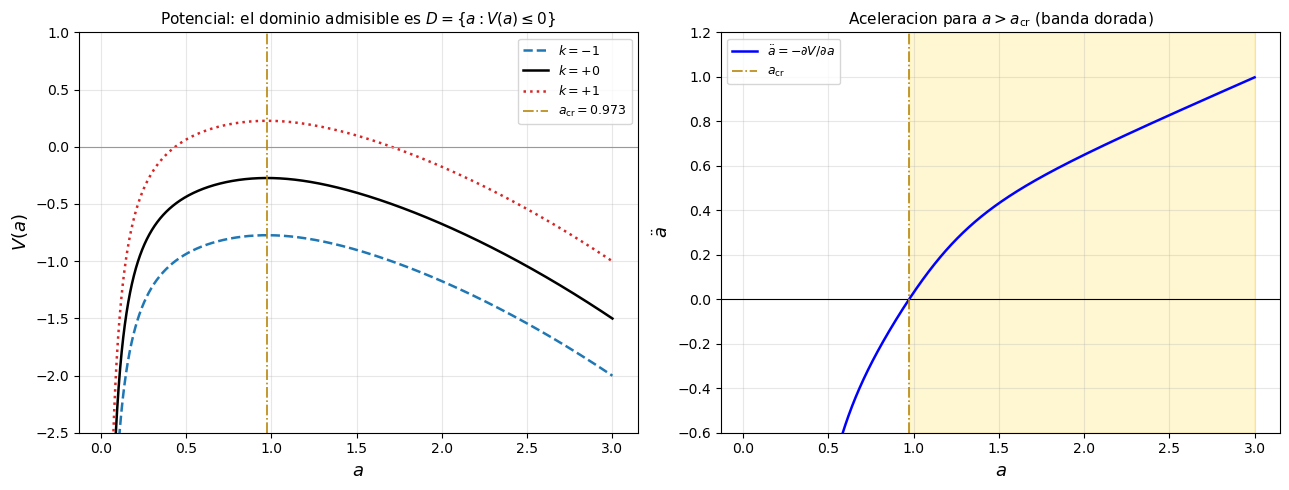

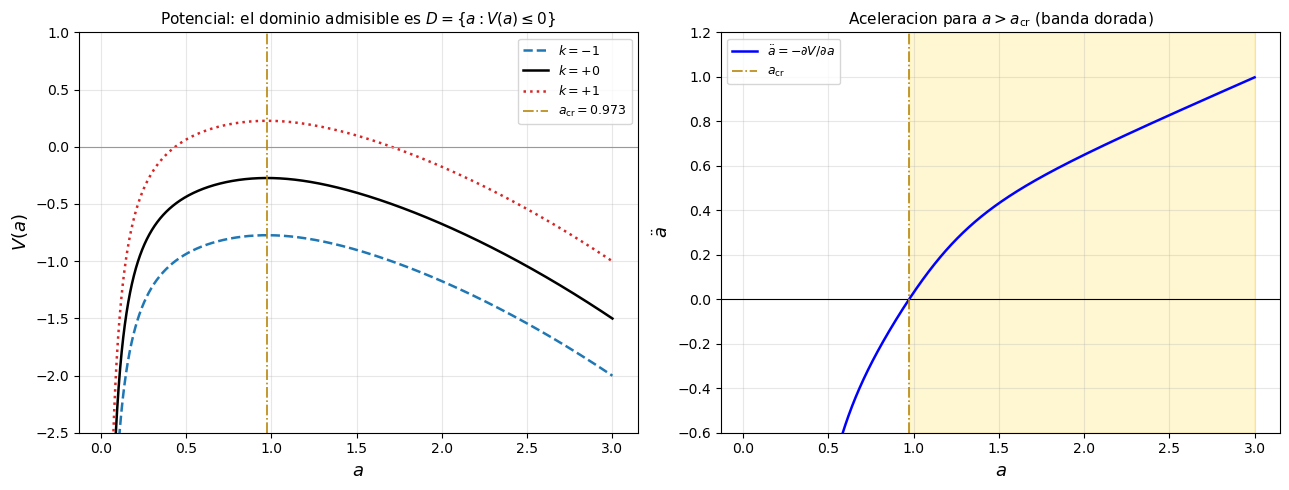

In [35]:
figura_hamiltoniana(CFG)

## 10. Comportamiento en el infinito: la esfera de Poincare

La proyeccion central sobre la esfera de Poincare,
$$X = H/\sqrt{1+H^2+\rho^2}, \quad  Y = \rho/ \sqrt{1+H^2+rho^2},  s = \sqrt{1-X^2-Y^2}$$

la cual lleva todo el plano al disco abierto y el INFINITO a la circunferencia unidad.


Si P y Q son polinomios de grado maximo n, entonces $p = s^n P(X/s, Y/s)$ y
$q = s^n Q(X/s, Y/s)$ son polinomios en (X, Y, s), y el campo reescalado
$Xdot = (s^2+Y^2) p - XY q$,    $Ydot = (s^2+X^2) q - XY p$
se extiende con continuidad al disco CERRADO. El reescalado divide el tiempo
por $s^(n-1) > 0$: conserva las orbitas y su orientacion.

En $s = 0$ solo sobreviven las partes homogeneas de grado maximo, y el campo
queda $(Xdot, Ydot) = G(\theta) (-Y, X)$, tangente a la circunferencia, con
$G(\theta) = \cos.Q_n(\cos,\sin) - \sin.P_n(\cos,\sin)$.
Luego el infinito es invariante y sus puntos criticos son los ceros de G.
Cero simple => punto hiperbolico; cero multiple => degenerado.

Con respecto a las ecs. (21)-(22) del articulo:
 1. Para que  P y Q sean POLINOMIOS, y eso solo ocurre si alpha
    es entero. Aqui se usa $\alpha = 1$, el gas de Chaplygin puro, que es el caso
    de su Fig. 2a. (Para alpha semientero el cambio $\rho = E^2$ vuelve polinomico
    el sistema: con $\alpha = 1/2$, $\rho^{3/2} = E^3$. Esa es una segunda razon para
    introducir $E = \sqrt(\rho)}, aparte de desdoblar el punto del infinito.)
 2. El articulo dice "n = 2 en el caso considerado". Para el gas con $\alpha = 1$
    el grado maximo es n = 3: P contiene $H^2 \rho$ y Q contiene $H \rho^2$. El n = 2
    encaja con los modelos de polvo + Lambda de sus Figs. 2b-d.

In [36]:
# Raices de G obtenidas a mano; la funcion verifica que no hay otras.
RAICES_G = {
    "Hrho": [(0.0, "0"), (np.pi / 2, "pi/2"), (np.pi, "pi"), (3 * np.pi / 2, "3pi/2")],
    "HE": [(0.0, "0"), (np.pi / 3, "pi/3"), (2 * np.pi / 3, "2pi/3"), (np.pi, "pi"),
           (4 * np.pi / 3, "4pi/3"), (5 * np.pi / 3, "5pi/3")],
}


def carta_zu(z, u, A):
    """Ecs. (21)-(22) en la carta z = 1/H, u = rho/H, para alpha = 1, n = 3."""
    dz = u * z + u ** 2 * z ** 2 / 6.0 - A * z ** 4 / 2.0
    du = -2.0 * u ** 2 + 3.0 * A * z ** 2 + u ** 3 * z / 6.0 - A * u * z ** 3 / 2.0
    return dz, du


def carta_vw(v, w, A):
    """La otra carta: w = 1/rho, v = H/rho."""
    dw = 3.0 * v * w - 3.0 * A * v * w ** 3
    dv = 2.0 * v ** 2 - w / 6.0 + A * w ** 3 / 2.0 - 3.0 * A * v ** 2 * w ** 2
    return dv, dw


def carta_zu_HE(z, u, A):
    """Sistema (H,E) tras dtau' = dtau/(2E), n = 5, en la carta z=1/H, u=E/H."""
    dz = u ** 5 * z / 3.0 + 2.0 * u ** 3 * z - A * u * z ** 5
    du = u ** 6 / 3.0 - u ** 4 + 3.0 * A * z ** 4 - A * u ** 2 * z ** 4
    return dz, du


def G_theta(theta, A, plano="Hrho"):
    """G(theta) sobre la circunferencia del infinito.

    (H,rho), n=3:  P_3 = -H^2 rho, Q_3 = -3 H rho^2  ->  G = -(1/2) sin^2(2 theta)
    (H,E),   n=5:  G = sin^4(theta) (4 sin^2(theta) - 3) / 3
    """
    c, s = np.cos(theta), np.sin(theta)
    if plano == "Hrho":
        return -2.0 * c ** 2 * s ** 2
    return s ** 4 * (4.0 * s ** 2 - 3.0) / 3.0


def raices_G(A, plano, h=1e-5):
    """(theta, nombre, es_simple, G'(theta)) para cada cero de G."""
    out = []
    for t, nombre in RAICES_G[plano]:
        dG = (G_theta(t + h, A, plano) - G_theta(t - h, A, plano)) / (2 * h)
        out.append((t, nombre, abs(dG) > 1e-6, dG))
    return out


def jac_fd_2(f, a, b, A, h=1e-6):
    """Jacobiana por diferencias centradas de una carta f(a, b, A)."""
    out = np.empty((2, 2))
    for j, (da, db) in enumerate([(h, 0.0), (0.0, h)]):
        f1, f2 = f(a + da, b + db, A), f(a - da, b - db, A)
        out[0, j] = (f1[0] - f2[0]) / (2 * h)
        out[1, j] = (f1[1] - f2[1]) / (2 * h)
    return out


def a_disco(H, Y):
    """Proyeccion central sobre la esfera de Poincare, vista en el disco."""
    H, Y = np.asarray(H, float), np.asarray(Y, float)
    D = np.sqrt(1.0 + H ** 2 + Y ** 2)
    return H / D, Y / D


def campo_disco(X, Y, A, plano):
    """Campo reescalado, continuo hasta el borde del disco cerrado."""
    s = np.sqrt(np.clip(1.0 - X ** 2 - Y ** 2, 0.0, None))
    if plano == "Hrho":        # n = 3
        p = s ** 3 * (A / 2.0) + s * (-Y ** 2 / 6.0) + (-X ** 2 * Y)
        q = s ** 2 * (3.0 * A * X) + (-3.0 * X * Y ** 2)
    else:                      # (H,E), n = 5
        p = s ** 4 * (A * Y) + (-2.0 * X ** 2 * Y ** 3 - Y ** 5 / 3.0)
        q = s ** 4 * (3.0 * A * X) + (-3.0 * X * Y ** 4)
    return (s ** 2 + Y ** 2) * p - X * Y * q, (s ** 2 + X ** 2) * q - X * Y * p


def analisis_infinito(cfg: Config):
    """Cartas proyectivas, equilibrios del ecuador y su clasificacion."""
    A = cfg.A_din
    titulo("10. Comportamiento en el infinito: la esfera de Poincare")

    print("grado maximo de P y Q (alpha = 1):")
    print("   P = A/2 - H^2 rho - rho^2/6   -> grados 0, 3, 2  ->  3")
    print("   Q = 3AH - 3 H rho^2           -> grados 1, 3     ->  3")
    print("   n = 3   (el articulo dice n = 2; eso corresponde a polvo + Lambda)")

    # OJO con el sentido de la reparametrizacion: dsigma/dtau = H^(n-1), luego
    # d/dsigma = z^(n-1) d/dtau, con n = 3 -> z^2. Asi dz/dsigma = -z^4 P.
    rng = np.random.default_rng(1)
    err = 0.0
    for _ in range(500):
        H, R = rng.normal(0, 2.0), abs(rng.normal(0, 2.0)) + 0.1
        if abs(H) < 0.3:
            continue
        z, u = 1.0 / H, R / H
        P, Q = PQ(H, R, 1.0, A)
        dz, du = carta_zu(z, u, A)
        ref_z, ref_u = -z ** 4 * P, z ** 3 * (Q - u * P)
        esc = max(abs(ref_z), abs(ref_u), 1e-12)
        err = max(err, abs(dz - ref_z) / esc, abs(du - ref_u) / esc)
    print(f"\nla carta (z,u) reproduce el sistema (20):  error relativo max = {err:.2e}")

    print("\npuntos criticos en el infinito, plano (H, rho):")
    for nombre, f in [("(z,u) = (0,0)   <-> H -> +-inf, rho/H -> 0", carta_zu),
                      ("(v,w) = (0,0)   <-> H/rho -> 0, rho -> +inf", carta_vw)]:
        J = jac_fd_2(f, 0.0, 0.0, A)
        print(f"  {nombre}")
        print(f"    residuo = {np.round(f(0.0, 0.0, A), 12)}")
        print(f"    J = {np.round(J, 10).tolist()}   autovalores = "
              f"{np.round(np.linalg.eigvals(J), 10)}")
        print("    -> no hiperbolico: la linealizacion no clasifica el punto")

    for plano, etiqueta in [("Hrho", "plano (H, rho),  n = 3"),
                            ("HE", "plano (H, E),    n = 5")]:
        print(f"\n{'=' * 78}\n{etiqueta}\n{'=' * 78}")
        print(f"{'theta':>12}{'theta/pi':>11}{'G':>12}{'dG/dtheta':>13}  tipo")
        for t, nombre, simple, dG in raices_G(A, plano):
            fis = ("  (rho>0)" if np.sin(t) > 1e-9
                   else ("  (rho=0)" if abs(np.sin(t)) < 1e-9 else "  (rho<0: no fisico)"))
            print(f"{t:12.6f}{t / np.pi:11.4f}{G_theta(t, A, plano):12.2e}{dG:13.3e}"
                  f"  {'SIMPLE' if simple else 'multiple (degenerado)'}{fis}")

        th = np.linspace(0, 2 * np.pi, 200001)
        d = np.min([np.abs((th - t + np.pi) % (2 * np.pi) - np.pi)
                    for t, _n in RAICES_G[plano]], axis=0)
        print(f"\n  min |G| a mas de 0.02 rad de esas raices = "
              f"{np.min(np.abs(G_theta(th[d > 0.02], A, plano))):.3e}"
              f"   -> no hay otras raices")
        print("  (la cota sale pequena porque junto a un cero multiple G es muy")
        print("   plana: en el plano (H,E) el cero de theta=0 es cuadruple)")
        if plano == "HE":
            print(f"\n  G(pi/2) = {G_theta(np.pi / 2, A, 'HE'):.6f}  != 0  ->  el punto "
                  f"compuesto (H=0, rho=+inf) ha desaparecido")
            print(f"  direccion de la parabola k=0:  arctan(sqrt(3))/pi = "
                  f"{np.arctan(np.sqrt(3)) / np.pi:.6f}  = 1/3  -> es la raiz simple")

    print(f"\n{'=' * 78}\nclasificacion de los puntos simples del infinito, plano (H,E)"
          f"\n{'=' * 78}")
    for u0, nombre in [(np.sqrt(3.0), "theta = pi/3  (H,E -> +inf,  E/H -> +sqrt(3))"),
                       (-np.sqrt(3.0), "theta = 2pi/3 (H -> -inf, E -> +inf, E/H -> -sqrt(3))")]:
        J = jac_fd_2(carta_zu_HE, 0.0, u0, A, h=1e-5)
        lam = np.linalg.eigvals(J)
        cerrada = np.array([9.0, 6.0]) * np.sqrt(3.0) * np.sign(u0)
        tipo = ("nodo inestable (repulsor)" if np.all(np.real(lam) > 0)
                else ("nodo estable (atractor)" if np.all(np.real(lam) < 0) else "silla"))
        print(f"\n  {nombre}")
        print(f"    residuo       = {np.round(carta_zu_HE(0.0, u0, A), 12)}")
        print(f"    autovalores   = {np.round(np.sort(np.real(lam))[::-1], 6)}")
        print(f"    forma cerrada = {np.round(np.sort(cerrada)[::-1], 6)}"
              f"   = {'+' if u0 > 0 else '-'}(9*sqrt(3), 6*sqrt(3))")
        print(f"    tipo          = {tipo}")

    print("\nLectura fisica: theta = pi/3 es la SINGULARIDAD INICIAL del modelo plano")
    print("en expansion (H, rho -> +inf) y es un repulsor; el de theta = 2pi/3 es su")
    print("imagen temporal invertida, el colapso final. El sistema es invariante bajo")
    print("(H, t) -> (-H, -t), que es la simetria que empareja los dos.")

    print("\nSobre la estabilidad estructural: el criterio de Peixoto pide puntos")
    print("hiperbolicos. En la region FINITA se cumple (parte 9). En el infinito no:")
    print("en (H,rho) los cuatro equilibrios del ecuador son degenerados, y el cambio")
    print("E=sqrt(rho) arregla dos pero deja degenerados los de theta = 0, pi. Esto NO")
    print("contradice la conclusion del articulo, porque su prueba se apoya en la")
    print("formulacion hamiltoniana (V'' < 0 => solo sillas), independiente del")
    print("infinito; pero la via de Peixoto necesitaria desingularizar antes esos dos")
    print("puntos con un blow-up, que no se hace aqui.")


Resultado

In [37]:
analisis_infinito(CFG)


10. Comportamiento en el infinito: la esfera de Poincare
grado maximo de P y Q (alpha = 1):
   P = A/2 - H^2 rho - rho^2/6   -> grados 0, 3, 2  ->  3
   Q = 3AH - 3 H rho^2           -> grados 1, 3     ->  3
   n = 3   (el articulo dice n = 2; eso corresponde a polvo + Lambda)

la carta (z,u) reproduce el sistema (20):  error relativo max = 1.61e-15

puntos criticos en el infinito, plano (H, rho):
  (z,u) = (0,0)   <-> H -> +-inf, rho/H -> 0
    residuo = [0. 0.]
    J = [[0.0, 0.0], [0.0, 0.0]]   autovalores = [0. 0.]
    -> no hiperbolico: la linealizacion no clasifica el punto
  (v,w) = (0,0)   <-> H/rho -> 0, rho -> +inf
    residuo = [0. 0.]
    J = [[0.0, -0.1666666667], [0.0, 0.0]]   autovalores = [0. 0.]
    -> no hiperbolico: la linealizacion no clasifica el punto

plano (H, rho),  n = 3
       theta   theta/pi           G    dG/dtheta  tipo
    0.000000     0.0000   -0.00e+00    0.000e+00  multiple (degenerado)  (rho=0)
    1.570796     0.5000   -7.50e-33    2.449e-16  multi

In [38]:

def figura_disco_poincare(cfg: Config):
    """Retrato global en el disco: la Fig. 2a del articulo y su Fig. 3."""
    A = cfg.A_din

    # comprobaciones antes de dibujar
    rng = np.random.default_rng(2)
    e1 = 0.0
    for _ in range(400):
        H, R = rng.normal(0, 2.0), abs(rng.normal(0, 2.0)) + 0.1
        X, Y = a_disco(H, R)
        s = np.sqrt(max(1.0 - X ** 2 - Y ** 2, 0.0))
        p = s ** 3 * (A / 2) + s * (-Y ** 2 / 6) + (-X ** 2 * Y)
        P = PQ(H, R, 1.0, A)[0]
        e1 = max(e1, abs(p / s ** 3 - P) / max(abs(P), 1))
    print(f"\np / s^n reproduce P(H,rho):  error relativo max = {e1:.2e}")

    th = np.linspace(0, 2 * np.pi, 361)
    for plano in ("Hrho", "HE"):
        U, V = campo_disco(np.cos(th), np.sin(th), A, plano)
        g = G_theta(th, A, plano)
        e2 = max(np.max(np.abs(U - g * (-np.sin(th)))),
                 np.max(np.abs(V - g * np.cos(th))))
        print(f"[{plano}] en el ecuador el campo es G(theta)(-Y,X):  error max = {e2:.2e}")

    Hf = np.logspace(0, 6, 7)
    print(f"angulo de la recta k=0 en el plano (H,E) al alejarse: "
          f"{np.round(np.degrees(np.arctan2(np.sqrt(3.0) * Hf, Hf)), 6)}"
          f"   -> pi/3 = {np.degrees(np.pi / 3):.6f} grados")

    fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4))
    for ax, plano in zip(axes, ["Hrho", "HE"]):
        g = np.linspace(-1, 1, 460)
        XX, YY = np.meshgrid(g, g)
        U, V = campo_disco(XX, YY, A, plano)
        fuera = XX ** 2 + YY ** 2 > 0.9985
        nrm = np.hypot(U, V)
        nrm = np.where(nrm > 0, nrm, 1.0)
        ax.streamplot(g, g, np.where(fuera, np.nan, U / nrm),
                      np.where(fuera, np.nan, V / nrm),
                      color="0.68", density=2.1, linewidth=0.6, arrowsize=0.8)

        ax.fill_between([-1.1, 1.1], -1.1, 0, color="0.88", alpha=0.95, zorder=3)
        ax.plot([-1.02, 1.02], [0, 0], "k-", lw=0.9, zorder=4)
        tt = np.linspace(0, 2 * np.pi, 600)
        ax.plot(np.cos(tt), np.sin(tt), "k-", lw=1.7, zorder=5)

        Hk = np.linspace(-400, 400, 40001)
        Yk = np.sqrt(3.0) * np.abs(Hk) if plano == "HE" else 3.0 * Hk ** 2
        ax.plot(*a_disco(Hk, Yk), "b-", lw=1.9, zorder=6)

        for nombre, H0, r0 in critical_points(1.0, A):
            re = np.real(np.linalg.eigvals(jacobian(H0, r0, 1.0, A)))
            est = (dict(marker="s", color="k") if re[0] * re[1] < 0 else
                   dict(marker="o", color="limegreen" if np.all(re < 0) else "white"))
            ax.plot(*a_disco(H0, np.sqrt(r0) if plano == "HE" else r0),
                    ms=9, mec="k", mew=1.3, ls="none", zorder=7, **est)

        for t, _nombre, simple, _dG in raices_G(A, plano):
            if np.sin(t) < -1e-9:
                continue                      # mitad no fisica
            ax.plot([np.cos(t)], [np.sin(t)], ls="none", ms=12, mew=1.5, mec="k",
                    marker="o" if simple else "D",
                    color="orange" if simple else "0.45", zorder=8)

        ax.set_aspect("equal")
        ax.set_xlim(-1.1, 1.1)
        ax.set_ylim(-0.13, 1.1)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(r"$(H,\rho)$ - Fig. 2a del paper, $n=3$" if plano == "Hrho"
                     else r"$(H,E)$, $E=\sqrt{\rho}$ - Fig. 3 del paper, $n=5$",
                     fontsize=11)

    fig.suptitle(f"Disco de Poincare: el infinito es la circunferencia "
                 f"($A={A:g}$, $\\alpha=1$)", fontsize=13)
    fig.tight_layout(rect=(0, 0.1, 1, 0.96))
    fig.legend(handles=[
        Line2D([], [], color="k", lw=1.7, label="infinito ($s=0$)"),
        Line2D([], [], color="b", lw=1.9, label=r"modelo plano $k=0$"),
        Line2D([], [], ls="none", marker="D", color="0.45", mec="k", ms=9,
               label="equilibrio degenerado (cero multiple de $G$)"),
        Line2D([], [], ls="none", marker="o", color="orange", mec="k", ms=9,
               label="equilibrio simple (hiperbolico)"),
        Line2D([], [], ls="none", marker="s", color="k", mec="k", ms=8,
               label="silla (Einstein)"),
        Line2D([], [], ls="none", marker="o", color="limegreen", mec="k", ms=8,
               label="de Sitter futuro"),
        Line2D([], [], ls="none", marker="o", color="white", mec="k", ms=8,
               label="de Sitter pasado"),
        Patch(facecolor="0.88", label="no fisico"),
    ], fontsize=8.5, loc="lower center", ncol=4, framealpha=0.95)
    guardar_figura(fig, "11_disco_poincare")
    return fig


p / s^n reproduce P(H,rho):  error relativo max = 1.19e-14
[Hrho] en el ecuador el campo es G(theta)(-Y,X):  error max = 1.75e-09
[HE] en el ecuador el campo es G(theta)(-Y,X):  error max = 1.67e-16
angulo de la recta k=0 en el plano (H,E) al alejarse: [60. 60. 60. 60. 60. 60. 60.]   -> pi/3 = 60.000000 grados


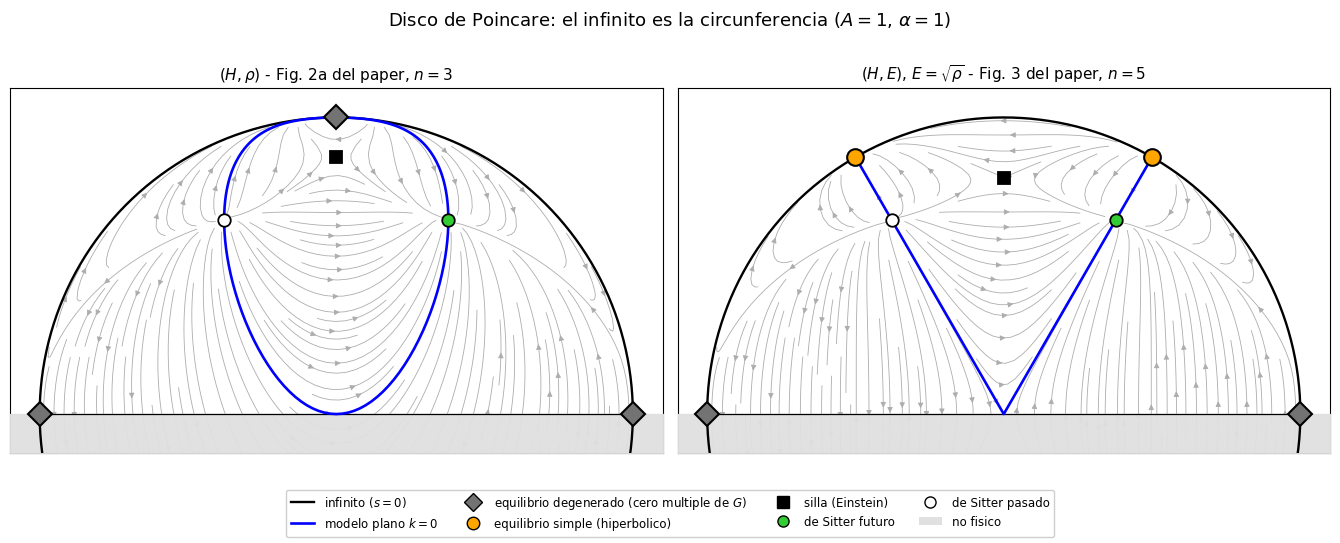

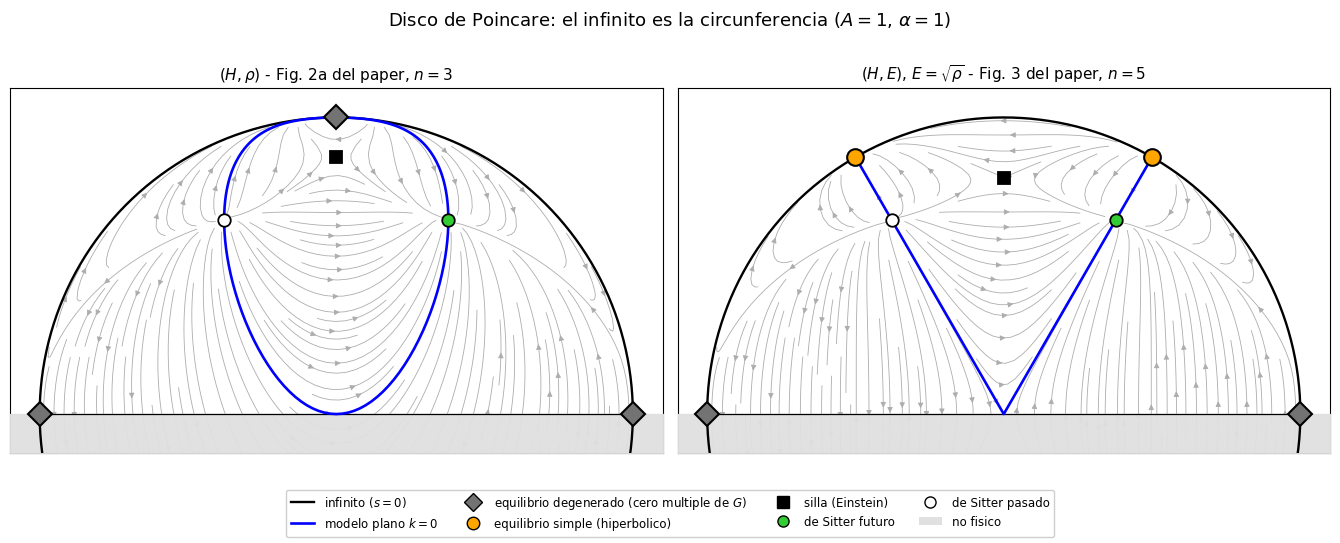

In [39]:
figura_disco_poincare(CFG)

## 11. El modelo UNIFICADO (Omega_m = 0) y la formacion de estructura

Esta parte cierra el circulo entre las dos mitades del archivo. En las partes
1-8 el gas convivia con una componente de materia Omega_m aparte; en las 9-10
el sistema dinamico es el del gas SOLO. La version que motiva el articulo es
justamente esta ultima: el gas da cuenta de la materia oscura Y la energia
oscura a la vez. Es la "materia oscura unificada" (UDM).

Con Omega_m = 0 el fondo es

$$E(a)^2 = f(a)^{1/(1+\alpha)}, \qquad f(a) = A_s + (1-A_s)\,a^{-3(1+\alpha)}$$

y queda un parametro menos: $(\alpha, A_s, H_0)$.

DOS CANTIDADES CLAVE

1. Parametro de materia efectivo. A z alto el gas se comporta como polvo:
   $E^2 \to (1-A_s)^{1/(1+alpha)} a^{-3}$, luego


  $$ \Omega_{m,eff} = (1 - A_s)^{1/(1+\alpha)}.$$
  

   Esto es lo que de verdad miden los datos de fondo, asi que el posterior
   sigue la curva $\Omega_{m,eff}$ = const: es una degeneracion entre alpha y A_s.

2. Velocidad del sonido. $c_s^2 = \alpha A / \rho^{1+alpha} = \alpha A_s / f(a)$.
   Vale 0 en el pasado, $\alpha*A_s$ hoy y tiende a alpha en el futuro. Y AQUI
   esta el problema del modelo: si el gas ES la materia oscura, una $c_s$ no
   nula le da presion, y la presion impide que la materia oscura colapse.

In [40]:
def f_unif(a, alpha, As):
    """f(a) = A_s + (1-A_s) a^(-3(1+alpha)); E^2 = f^(1/(1+alpha))."""
    return As + (1.0 - As) * np.asarray(a, float) ** (-3.0 * (1.0 + alpha))


def E_unif(a, alpha, As):
    """E(a) del modelo unificado (Omega_m = 0)."""
    return f_unif(a, alpha, As) ** (0.5 / (1.0 + alpha))


def dlnE_dlna_unif(a, alpha, As):
    """d ln E / d ln a = -(3/2) (1-A_s) a^(-3(1+alpha)) / f(a).

    Vale -3/2 en epoca de materia y 0 en de Sitter.
    """
    a = np.asarray(a, float)
    return -1.5 * (1.0 - As) * a ** (-3.0 * (1.0 + alpha)) / f_unif(a, alpha, As)


def cs2_unif(a, alpha, As):
    """Velocidad del sonido al cuadrado, en unidades de c: alpha A_s / f(a)."""
    return alpha * As / f_unif(a, alpha, As)


def Om_eff(alpha, As):
    """Parametro de materia efectivo (1-A_s)^(1/(1+alpha))."""
    return (1.0 - As) ** (1.0 / (1.0 + alpha))


def chi2_unif(p):
    """chi^2 del modelo unificado frente a H(z) (+ Pantheon si esta cargado)."""
    alpha, As, H0 = p
    if not (0.0 < alpha <= 1.0 and 0.0 < As < 1.0 and 20.0 < H0 < 100.0):
        return np.inf
    Hth = H0 * E_unif(1.0 / (1.0 + Z_HZ), alpha, As)
    if not np.all(np.isfinite(Hth)):
        return np.inf
    c = float(np.sum(((H_OBS - Hth) / H_ERR) ** 2))
    if PANTHEON is not None:
        c += PANTHEON.chi2(alpha, As, H0, 0.0)
    return c


def log_post_unif(p):
    c = chi2_unif(p)
    return -np.inf if not np.isfinite(c) else -0.5 * c


def verificaciones_unificado():
    """El fondo unificado, comprobado contra el resto del archivo."""
    titulo("11. El modelo unificado (Omega_m = 0)")

    print("comprobaciones del fondo:")
    print(f"  E(a=1) = {E_unif(1.0, 0.5, 0.75):.12f}   (debe ser 1)")
    at = np.array([1e-4, 1e-2, 1.0, 1e3])
    print(f"  dlnE/dlna en a = {at}:\n     {np.round(dlnE_dlna_unif(at, 0.5, 0.75), 6)}"
          f"   (-3/2 en materia, 0 en de Sitter)")
    print(f"  c_s^2(a=1)      = {cs2_unif(1.0, 0.5, 0.75):.12f}  vs  alpha*A_s = {0.5 * 0.75}")
    print(f"  c_s^2(a -> inf) = {cs2_unif(1e6, 0.5, 0.75):.12f}  vs  alpha     = {0.5}")
    print(f"  c_s^2(a -> 0)   = {cs2_unif(1e-6, 0.5, 0.75):.3e}  (-> 0)")

    z = np.array([0.0, 0.5, 1.0, 2.0])
    d = np.max(np.abs(E_unif(1 / (1 + z), 0.5, 0.75) - E_model(z, 0.5, 0.75, 0.0)))
    print(f"  coherencia con E_model(..., Om=0): max dif = {d:.2e}")

    # alpha -> 0 : el gas unificado ES LCDM, con 1-A_s haciendo de Omega_m
    print("\nlimite alpha -> 0 (debe ser LCDM exacto con Om = 1 - A_s):")
    for As in (0.70, 0.74, 0.80):
        aa = np.array([0.2, 0.5, 1.0])
        E0 = E_unif(aa, 1e-10, As)
        Elcdm = np.sqrt((1 - As) * aa ** -3 + As)
        print(f"  A_s = {As}:  max|E_unif - E_LCDM| = {np.max(np.abs(E0 - Elcdm)):.2e}"
              f"   (Om = {1 - As:.2f})")

    print("\nparametro de materia efectivo Om_eff = (1-A_s)^(1/(1+alpha)):")
    print(f"{'alpha':>10}{'A_s':>8}{'analitico':>12}{'numerico':>12}")
    for al, As in [(1.0, 0.75), (0.5, 0.80), (1e-5, 0.74)]:
        aa = 1e-5                      # a z alto, E^2 a^3 -> Om_eff
        print(f"{al:>10.0e}{As:>8}{Om_eff(al, As):>12.6f}"
              f"{E_unif(aa, al, As) ** 2 * aa ** 3:>12.6f}")


Resultados

In [41]:
verificaciones_unificado()


11. El modelo unificado (Omega_m = 0)
comprobaciones del fondo:
  E(a=1) = 1.000000000000   (debe ser 1)
  dlnE/dlna en a = [1.e-04 1.e-02 1.e+00 1.e+03]:
     [-1.5   -1.5   -0.375 -0.   ]   (-3/2 en materia, 0 en de Sitter)
  c_s^2(a=1)      = 0.375000000000  vs  alpha*A_s = 0.375
  c_s^2(a -> inf) = 0.500000000000  vs  alpha     = 0.5
  c_s^2(a -> 0)   = 1.500e-27  (-> 0)
  coherencia con E_model(..., Om=0): max dif = 0.00e+00

limite alpha -> 0 (debe ser LCDM exacto con Om = 1 - A_s):
  A_s = 0.7:  max|E_unif - E_LCDM| = 3.39e-10   (Om = 0.30)
  A_s = 0.74:  max|E_unif - E_LCDM| = 3.51e-10   (Om = 0.26)
  A_s = 0.8:  max|E_unif - E_LCDM| = 3.63e-10   (Om = 0.20)

parametro de materia efectivo Om_eff = (1-A_s)^(1/(1+alpha)):
     alpha     A_s   analitico    numerico
     1e+00    0.75    0.500000    0.500000
     5e-01     0.8    0.341995    0.341995
     1e-05    0.74    0.260004    0.260004


In [42]:
def muestrear_unificado(cfg: Config):
    """MCMC de 3 parametros (alpha, A_s, H0) para el modelo unificado."""
    titulo("11.1 Ajuste del modelo unificado", nivel=2)
    ndim = 3

    semilla = minimize(chi2_unif, [0.05, 0.74, 70.0], method="Nelder-Mead",
                       options={"maxiter": 20000, "xatol": 1e-8, "fatol": 1e-8})
    centro = np.clip(semilla.x, [1e-3, 1e-3, 21.0], [0.999, 0.999, 99.0])
    print("centro de arranque (minimo del chi^2):", np.round(centro, 4))

    rng = np.random.default_rng(cfg.semilla)
    p0 = []
    while len(p0) < cfg.caminantes:
        cand = centro + np.array([0.02, 0.01, 0.5]) * rng.standard_normal(ndim)
        if np.isfinite(log_post_unif(cand)):
            p0.append(cand)

    sampler = emcee.EnsembleSampler(
        cfg.caminantes, ndim, log_post_unif,
        moves=[(emcee.moves.DEMove(), 0.8), (emcee.moves.DESnookerMove(), 0.2)])
    sampler.run_mcmc(np.array(p0), cfg.pasos, progress=True)

    tau = sampler.get_autocorr_time(tol=0)
    tau_max = float(np.nanmax(tau))
    burn = int(min(5 * tau_max, 0.3 * cfg.pasos))
    thin = max(1, int(tau_max / 2))
    flat = sampler.get_chain(discard=burn, thin=thin, flat=True)
    lp = sampler.get_log_prob(discard=burn, thin=thin, flat=True)
    print(f"tau = {np.round(tau, 1)}   aceptacion = "
          f"{np.mean(sampler.acceptance_fraction):.3f}   muestras = {len(flat)}")

    best = flat[int(np.argmax(lp))]
    print(f"\n{'Parametro':<10}{'mediana':>11}{'+68%':>9}{'-68%':>9}{'MAP':>11}")
    print("-" * 50)
    for i, nombre in enumerate(["alpha", "A_s", "H0"]):
        q16, q50, q84 = np.percentile(flat[:, i], [16, 50, 84])
        print(f"{nombre:<10}{q50:11.4f}{q84-q50:9.4f}{q50-q16:9.4f}{best[i]:11.4f}")

    om = Om_eff(flat[:, 0], flat[:, 1])
    q16, q50, q84 = np.percentile(om, [16, 50, 84])
    print(f"{'Om_eff':<10}{q50:11.4f}{q84-q50:9.4f}{q50-q16:9.4f}"
          f"{Om_eff(best[0], best[1]):11.4f}   <- cantidad derivada")

    print(f"\n  alpha < {np.percentile(flat[:, 0], 95):.4f}  (95% CL)")
    print(f"  corr(alpha, A_s) = {np.corrcoef(flat[:, 0], flat[:, 1])[0, 1]:+.3f}"
          f"   <- la degeneracion Om_eff = const")
    print(f"  dispersion relativa de Om_eff = {np.std(om) / np.mean(om):.4f}"
          f"   (muy pequena: es lo que miden los datos)")

    r = minimize(chi2_unif, best, method="Nelder-Mead",
                 options={"maxiter": 20000, "xatol": 1e-8, "fatol": 1e-8})
    gl = len(Z_HZ) - 3 + (PANTHEON.n - 1 if PANTHEON is not None else 0)
    print(f"\nchi^2_min = {r.fun:.4f}   g.l. = {gl}   chi^2/g.l. = {r.fun / gl:.4f}")
    print(f"minimo en  alpha = {r.x[0]:.3e}   A_s = {r.x[1]:.6f}   H0 = {r.x[2]:.3f}"
          f"   Om_eff = {Om_eff(r.x[0], r.x[1]):.6f}")
    return flat, lp, best, float(r.fun), r.x


def comparar_unificado(chi2_unif_min, chi2_gcg, chi2_lcdm):
    """Compara los tres modelos: unificado (k=3), GCG con Om libre (k=4), LCDM (k=2)."""
    titulo("11.2 Comparacion de los tres modelos", nivel=2)
    n_dat = len(Z_HZ) + (PANTHEON.n if PANTHEON is not None else 0)
    extra = 1 if PANTHEON is not None else 0      # la magnitud absoluta M

    filas = [("GCG unificado (Om=0)", chi2_unif_min, 3 + extra),
             ("GCG con Om libre", chi2_gcg, 4 + extra),
             ("LCDM", chi2_lcdm, 2 + extra)]
    print(f"{'modelo':<24}{'chi2_min':>11}{'k':>4}{'AIC':>10}{'BIC':>10}")
    print("-" * 59)
    for nombre, c, k in filas:
        print(f"{nombre:<24}{c:11.4f}{k:4d}{c + 2 * k:10.2f}"
              f"{c + k * np.log(n_dat):10.2f}")

    print("\nLos tres dan el MISMO chi^2 minimo, porque los tres contienen a LCDM:")
    print("  - el unificado, en alpha -> 0 (entonces es Lambda + polvo con Om = 1-A_s)")
    print("  - el de Om libre, en A_s -> 1 (para cualquier alpha)")
    print("El unificado gana en AIC/BIC al de Om libre por tener un parametro menos,")
    print("pero LCDM sigue ganando a los dos: ninguno compra mejora de ajuste.")
    print("\nDiferencia importante con la parte 7: al quitar Omega_m la degeneracion")
    print("A_s-Om desaparece y los datos de FONDO si acotan alpha (ver la tabla de")
    print("perfilado de abajo). Lo que pasa es que lo acotan cinco ordenes de")
    print("magnitud peor que la formacion de estructura (parte 11.3).")



Resultados


In [43]:

flat_u, lp_u, best_u, chi2_u, x_u = muestrear_unificado(CFG)
comparar_unificado(chi2_u, chi2_min, chi2_lcdm)


------------------------------------------------------------------------------
11.1 Ajuste del modelo unificado
------------------------------------------------------------------------------
centro de arranque (minimo del chi^2): [1.00000e-03 7.36700e-01 6.99361e+01]


100%|██████████| 20000/20000 [01:26<00:00, 231.61it/s]


tau = [35.4 29.8 24.3]   aceptacion = 0.212   muestras = 55968

Parametro     mediana     +68%     -68%        MAP
--------------------------------------------------
alpha          0.1780   0.2417   0.1294     0.0027
A_s            0.7948   0.0623   0.0461     0.7370
H0            71.6222   2.7080   2.5217    69.8742
Om_eff         0.2605   0.0237   0.0206     0.2639   <- cantidad derivada

  alpha < 0.6292  (95% CL)
  corr(alpha, A_s) = +0.912   <- la degeneracion Om_eff = const
  dispersion relativa de Om_eff = 0.0863   (muy pequena: es lo que miden los datos)

chi^2_min = 17.8282   g.l. = 32   chi^2/g.l. = 0.5571
minimo en  alpha = 1.842e-15   A_s = 0.736661   H0 = 69.936   Om_eff = 0.263339

------------------------------------------------------------------------------
11.2 Comparacion de los tres modelos
------------------------------------------------------------------------------
modelo                     chi2_min   k       AIC       BIC
----------------------------------------

In [47]:
def perfil_alpha_unificado(n=9):
    """chi^2 perfilado sobre (A_s, H0) a alpha fijo: cuanto acota el FONDO a alpha."""
    print("\nchi^2 perfilado sobre (A_s, H0) con alpha fijo:")
    print(f"\n{'alpha':>8}{'A_s':>10}{'H0':>9}{'Om_eff':>9}{'chi2':>10}{'dchi2':>9}")
    print("-" * 55)
    alphas = np.concatenate(([1e-4], np.linspace(0.05, 1.0, n - 1)))
    chi2s, filas = [], []
    for al in alphas:
        r = minimize(lambda q: chi2_unif([al, q[0], q[1]]), [0.75, 70.0],
                     method="Nelder-Mead",
                     options={"maxiter": 20000, "xatol": 1e-8, "fatol": 1e-8})
        chi2s.append(r.fun)
        filas.append((al, r.x[0], r.x[1], Om_eff(al, r.x[0]), r.fun))
    c0 = min(chi2s)
    for al, As, H0, om, c in filas:
        print(f"{al:>8.3f}{As:>10.4f}{H0:>9.3f}{om:>9.4f}{c:>10.4f}{c - c0:>9.4f}")
    print("\n  Om_eff se mantiene casi constante: es lo unico que fija el fondo.")
    print("  Delta chi^2 = 1 y 4 marcan 1 y 2 sigma para un parametro.")
    return np.array(alphas), np.array(chi2s)


# ---------------------------------------------------------------------------
# 11.3 Formacion de estructura: por que el modelo unificado no funciona
# ---------------------------------------------------------------------------
#
# Si el gas es la materia oscura, su presion se opone al colapso gravitatorio.
# Igualando el termino de presion c_s^2 k^2/a^2 al de gravedad (3/2)H^2 sale el
# numero de onda COMOVIL de Jeans
#
#     k_J(a) = (H0/c) a E(a) sqrt( 3 / (2 c_s^2(a)) ).
#
# Los modos con k > k_J no crecen: oscilan como ondas sonoras. Para que el
# modelo forme estructura en las escalas donde se mide el espectro de potencias
# de materia (k ~ 0.1-0.2 1/Mpc) hace falta k_J mayor que esas k, y como
# k_J ~ 1/sqrt(alpha), eso exige un alpha diminuto.

def k_jeans(a, alpha, As, H0):
    """Numero de onda comovil de Jeans, en 1/Mpc."""
    return (H0 / C_LIGHT) * a * E_unif(a, alpha, As) * np.sqrt(1.5 / cs2_unif(a, alpha, As))


def cota_alpha_jeans(k_obs, As, H0):
    """alpha maximo para que k_J(a=1) > k_obs.  De (H0/c)sqrt(3/(2 alpha As)) = k_obs."""
    return 1.5 * (H0 / C_LIGHT) ** 2 / (As * k_obs ** 2)


def crecimiento(k_Mpc, alpha, As, H0=70.0, a_ini=1e-3, n=3000):
    """Integra la ecuacion de Jeans en fondo expansivo, con ln a como tiempo:

        d2d/dlna2 + (2 + dlnE/dlna) dd/dlna
                  + [c_s^2 kappa^2/(a^2 E^2) - 3/2] d = 0,   kappa = k c / H0.

    Es la ecuacion estandar para un fluido con presion en el limite
    sub-horizonte. La ecuacion completa del gas de Chaplygin (Sandvik et al.
    2004, su ec. 6) lleva terminos adicionales en w y w'; no cambian la
    conclusion, pero si los detalles finos.

    Condicion inicial en plena epoca de materia: el modo creciente es d ~ a.
    """
    kappa = k_Mpc * C_LIGHT / H0

    def rhs(lna, y):
        a = np.exp(lna)
        d, dp = y
        termino = (cs2_unif(a, alpha, As) * kappa ** 2
                   / (a ** 2 * E_unif(a, alpha, As) ** 2) - 1.5)
        return [dp, -(2.0 + dlnE_dlna_unif(a, alpha, As)) * dp - termino * d]

    sol = solve_ivp(rhs, (np.log(a_ini), 0.0), [1.0, 1.0],
                    t_eval=np.linspace(np.log(a_ini), 0.0, n),
                    rtol=1e-8, atol=1e-12)
    return np.exp(sol.t), sol.y[0]




Resultado

In [48]:
alphas_p, chi2s_p = perfil_alpha_unificado()




chi^2 perfilado sobre (A_s, H0) con alpha fijo:

   alpha       A_s       H0   Om_eff      chi2    dchi2
-------------------------------------------------------
   0.000    0.7367   69.937   0.2633   17.8285   0.0000
   0.050    0.7544   70.429   0.2626   18.0171   0.1885
   0.186    0.7977   71.684   0.2598   18.6681   0.8396
   0.321    0.8344   72.819   0.2564   19.4808   1.6523
   0.457    0.8651   73.835   0.2529   20.4084   2.5799
   0.593    0.8904   74.741   0.2495   21.4105   3.5819
   0.729    0.9112   75.545   0.2464   22.4539   4.6253
   0.864    0.9282   76.256   0.2434   23.5123   5.6838
   1.000    0.9420   76.885   0.2408   24.5658   6.7373

  Om_eff se mantiene casi constante: es lo unico que fija el fondo.
  Delta chi^2 = 1 y 4 marcan 1 y 2 sigma para un parametro.


In [49]:
def analisis_estructura(As=0.74, H0=70.0):
    """La cota sobre alpha que impone la formacion de estructura."""
    titulo("11.3 Formacion de estructura: el limite sobre alpha", nivel=2)

    print(f"escala de Jeans hoy (a=1), A_s = {As}, H0 = {H0}:")
    print(f"{'alpha':>10}{'c_s^2(0)':>12}{'k_J [1/Mpc]':>14}{'2pi/k_J [Mpc]':>16}")
    for al in (1.0, 1e-1, 1e-3, 1e-5, 1e-7):
        kj = k_jeans(1.0, al, As, H0)
        print(f"{al:>10.0e}{cs2_unif(1.0, al, As):>12.2e}{kj:>14.3e}{2 * np.pi / kj:>16.1f}")

    print("\ncota sobre alpha exigiendo k_J(a=1) > k_obs:")
    for k_obs in (0.1, 0.2):
        print(f"  k_obs = {k_obs} 1/Mpc  ->  alpha < {cota_alpha_jeans(k_obs, As, H0):.2e}")
    print("\n  Coincide con el limite publicado, alpha <~ 1e-5 (Sandvik, Tegmark,")
    print("  Zaldarriaga & Waga, Phys. Rev. D 69, 123524, 2004).")

    # crecimiento explicito
    print(f"\ncrecimiento de delta hasta a=1 para k = 0.1 1/Mpc (A_s = {As}):")
    print(f"{'alpha':>10}{'delta(1)':>14}{'delta/delta_p=0':>18}{'oscilaciones':>14}")
    _, d_ref = crecimiento(0.1, 0.0, As, H0)
    for al in (0.0, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1.0):
        _, d = crecimiento(0.1, al, As, H0)
        n_osc = int(np.sum(np.diff(np.sign(d)) != 0))
        print(f"{al:>10.0e}{d[-1]:>14.3f}{d[-1] / d_ref[-1]:>18.4f}{n_osc:>14d}")
    print("\n  Hasta alpha ~ 1e-6 el crecimiento es el de la materia sin presion.")
    print("  En alpha ~ 1e-5 ya se pierde ~20%, y a partir de 1e-4 delta OSCILA:")
    print("  cambia de signo, no crece. Eso es incompatible con que el gas sea la")
    print("  materia oscura que formo las galaxias.")


Resultado

In [50]:
analisis_estructura()


------------------------------------------------------------------------------
11.3 Formacion de estructura: el limite sobre alpha
------------------------------------------------------------------------------
escala de Jeans hoy (a=1), A_s = 0.74, H0 = 70.0:
     alpha    c_s^2(0)   k_J [1/Mpc]   2pi/k_J [Mpc]
     1e+00    7.40e-01     3.324e-04         18900.5
     1e-01    7.40e-02     1.051e-03          5976.9
     1e-03    7.40e-04     1.051e-02           597.7
     1e-05    7.40e-06     1.051e-01            59.8
     1e-07    7.40e-08     1.051e+00             6.0

cota sobre alpha exigiendo k_J(a=1) > k_obs:
  k_obs = 0.1 1/Mpc  ->  alpha < 1.11e-05
  k_obs = 0.2 1/Mpc  ->  alpha < 2.76e-06

  Coincide con el limite publicado, alpha <~ 1e-5 (Sandvik, Tegmark,
  Zaldarriaga & Waga, Phys. Rev. D 69, 123524, 2004).

crecimiento de delta hasta a=1 para k = 0.1 1/Mpc (A_s = 0.74):
     alpha      delta(1)   delta/delta_p=0  oscilaciones
     0e+00       870.768            1.0000   

In [ ]:
def figura_unificado(alphas, chi2s, flat_u=None):
    """Perfilado de alpha y la degeneracion Om_eff = const."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

    ax1.plot(alphas, chi2s - chi2s.min(), "b-o", ms=4, lw=1.6)
    for d, et, c in [(1.0, r"$1\sigma$", "0.4"), (4.0, r"$2\sigma$", "0.6")]:
        ax1.axhline(d, color=c, ls="--", lw=1.0)
        ax1.text(0.985, d, et, va="bottom", ha="right", fontsize=9, color=c,
                 transform=ax1.get_yaxis_transform())
    ax1.set_xlabel(r"$\alpha$", fontsize=13)
    ax1.set_ylabel(r"$\Delta\chi^2$ perfilado sobre $(A_s, H_0)$", fontsize=12)
    ax1.set_title("El fondo SI acota $\\alpha$ al quitar $\\Omega_m$", fontsize=11)
    ax1.grid(alpha=0.3)

    ag = np.linspace(1e-3, 1.0, 300)
    for om in (0.24, 0.26, 0.28, 0.30):
        # Om_eff = (1-As)^(1/(1+a)) = om  ->  As = 1 - om^(1+a)
        ax2.plot(ag, 1.0 - om ** (1.0 + ag), lw=1.5,
                 label=rf"$\Omega_{{m,\rm eff}}={om:.2f}$")
    if flat_u is not None:
        sub = flat_u[np.random.default_rng(0).choice(len(flat_u),
                                                     min(3000, len(flat_u)),
                                                     replace=False)]
        ax2.plot(sub[:, 0], sub[:, 1], ".", ms=1.2, color="crimson", alpha=0.25,
                 zorder=0, label="posterior")
    ax2.set_xlabel(r"$\alpha$", fontsize=13)
    ax2.set_ylabel(r"$A_s$", fontsize=13)
    ax2.set_xlim(0, 1)
    ax2.set_ylim(0.6, 1.0)
    ax2.set_title(r"El posterior sigue $\Omega_{m,\rm eff}=$ const", fontsize=11)
    ax2.legend(fontsize=9, loc="lower right")
    ax2.grid(alpha=0.3)

    fig.tight_layout()
    guardar_figura(fig, "12_unificado")
    return fig


Resultado

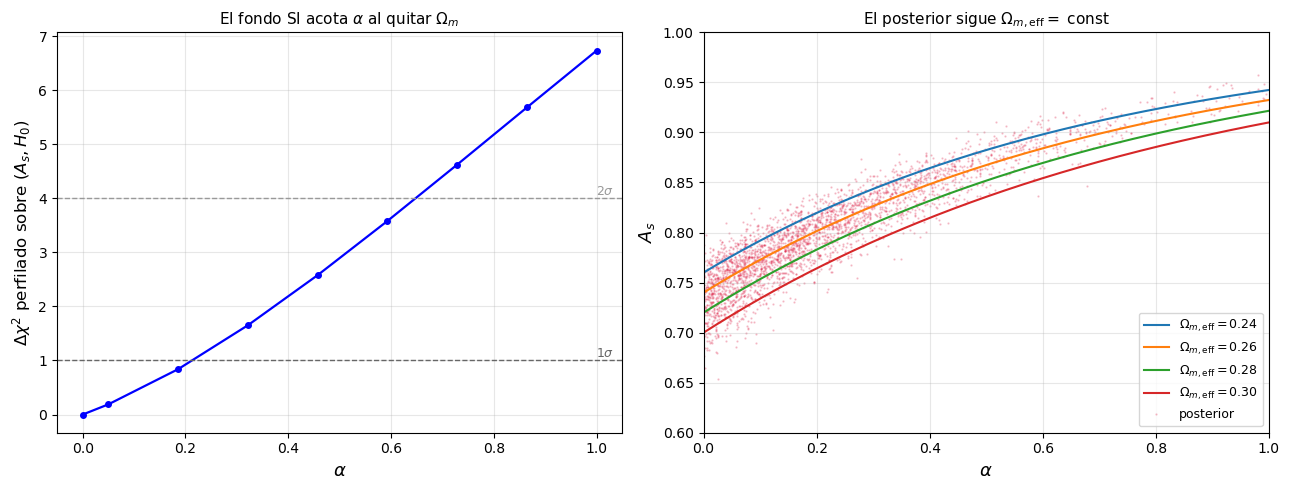

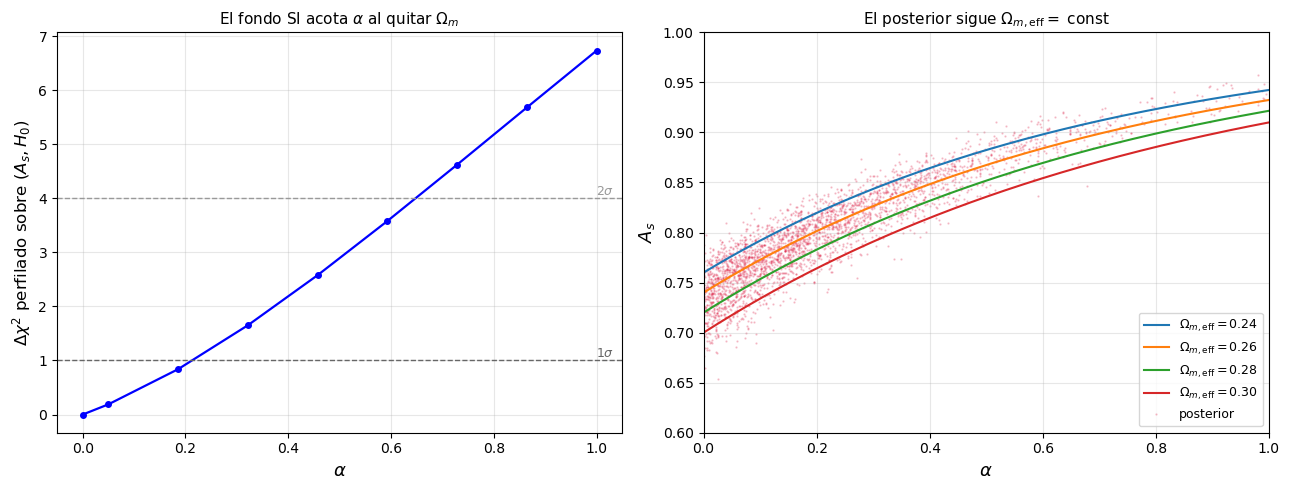

In [52]:

figura_unificado(alphas_p, chi2s_p, flat_u)

In [ ]:
def figura_estructura(As=0.74, H0=70.0):
    """c_s^2(a), la escala de Jeans y el crecimiento de delta."""
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    ag = np.logspace(-3, 0, 400)

    # Un mismo alpha lleva el mismo color en los tres paneles: si cada panel
    # usara su propia lista de alphas, habria que releer la leyenda cada vez.
    SERIES = [(1e-6, "C0"), (1e-5, "C2"), (1e-4, "C1"), (1e-3, "C3")]

    ax = axes[0]
    for al, c in SERIES:
        ax.loglog(ag, cs2_unif(ag, al, As), color=c, lw=1.7,
                  label=rf"$\alpha=10^{{{np.log10(al):.0f}}}$")
    ax.set_xlabel("$a$", fontsize=13)
    ax.set_ylabel(r"$c_s^2\ [c^2]$", fontsize=13)
    ax.set_title(r"Velocidad del sonido: $c_s^2=\alpha A_s/f(a)$", fontsize=11)
    ax.legend(fontsize=8.5)
    ax.grid(alpha=0.3, which="both")

    ax = axes[1]
    for al, c in SERIES:
        ax.loglog(ag, k_jeans(ag, al, As, H0), color=c, lw=1.7,
                  label=rf"$\alpha=10^{{{np.log10(al):.0f}}}$")
    ax.axhspan(0.1, 0.2, color="green", alpha=0.18)
    ax.text(1.2e-3, 0.28, "escalas donde se mide\nel espectro de materia",
            fontsize=8, color="darkgreen")
    ax.set_xlabel("$a$", fontsize=13)
    ax.set_ylabel(r"$k_J$ comovil $[\mathrm{Mpc}^{-1}]$", fontsize=13)
    ax.set_title(r"Escala de Jeans: los modos con $k>k_J$ no crecen", fontsize=11)
    ax.legend(fontsize=8.5, loc="upper right")   # abajo a la izq. tapa la banda verde
    ax.grid(alpha=0.3, which="both")

    ax = axes[2]
    a_ref, d_ref = crecimiento(0.1, 0.0, As, H0)
    ax.plot(a_ref, d_ref / d_ref[0], "k-", lw=2.2, label=r"sin presion ($\alpha=0$)")
    for al, c in SERIES:
        a_, d_ = crecimiento(0.1, al, As, H0)
        ax.plot(a_, d_ / d_[0], color=c, lw=1.5,
                label=rf"$\alpha=10^{{{np.log10(al):.0f}}}$")
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_xscale("log")
    ax.set_xlabel("$a$", fontsize=13)
    ax.set_ylabel(r"$\delta(a)/\delta(a_i)$", fontsize=13)
    ax.set_title(r"Crecimiento a $k=0.1\ \mathrm{Mpc}^{-1}$", fontsize=11)
    ax.legend(fontsize=8.5, loc="upper left")
    ax.grid(alpha=0.3)

    fig.suptitle("Por que el gas de Chaplygin no puede ser la materia oscura "
                 f"($A_s={As}$)", fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    guardar_figura(fig, "13_estructura")
    return fig



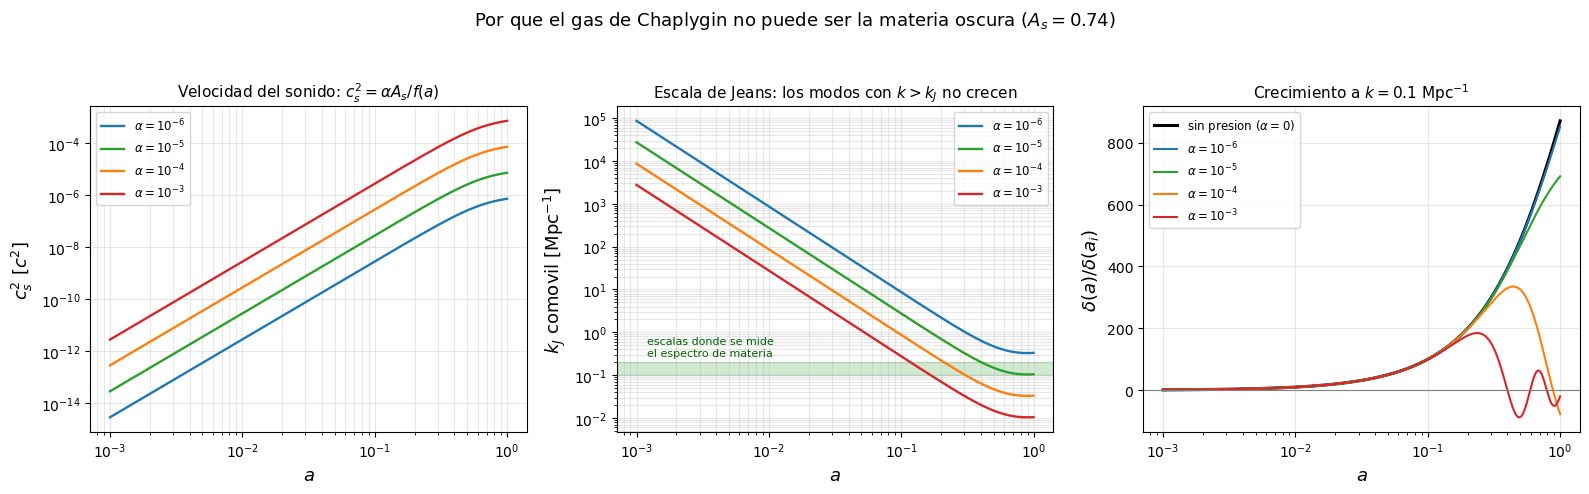

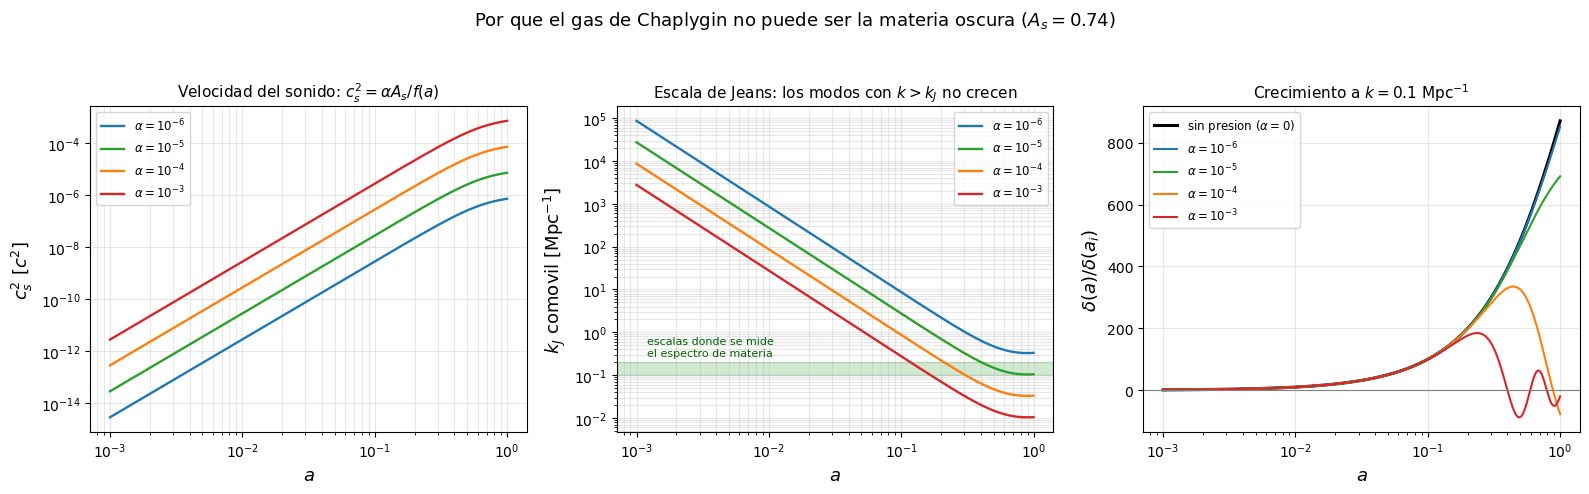

In [ ]:
figura_estructura()

  * El FONDO (H(z), supernovas) admite el modelo unificado sin problema: el
    $\chi^2$ minimo es identico al de $\Lambda CDM$, y con un parametro menos que el GCG de
    $\Omega_m$ libre. Al quitar $\Omega_m$ desaparece la degeneracion $A_s-Om$ y los
    datos de fondo si acotan $\alpha$, pero solo al nivel de $\alpha <~ 0.6$.

  * La FORMACION DE ESTRUCTURA exige $alpha <~ 1e-5$: cinco ordenes de magnitud
    mas estricto. Y es una exigencia ineludible, porque en el modelo unificado
    el gas ES la materia oscura: no hay otra componente que forme las galaxias.

  * En $\alpha <~ 1e-5$ el modelo es indistinguible de LCDM en cualquier
    observable: $c_s^2 ~ 0$ y el gas se comporta como Lambda + polvo con
    $Omega_m = 1 - A_s$. El unico parametro que lo distinguia deja de tener
    efecto observable.

Esa es la conclusion de Sandvik, Tegmark, Zaldarriaga & Waga (2004), y el
motivo del titulo de su articulo: "The end of unified dark matter?". El gas de
Chaplygin generalizado como materia oscura unificada o bien esta descartado, o
bien es LCDM con otro nombre.

Conviene no confundir esto con el analisis dinamico de las partes 9 y 10: alli
el modelo es perfectamente consistente y estructuralmente estable. Lo que falla
no es su dinamica de fondo, sino su capacidad de agrupar materia.

## Conclusiones


LO QUE LOS DATOS SI DICEN
  * LCDM es el limite A_s -> 1, y lo es para cualquier alpha. El minimo del
    chi^2 del gas cae exactamente ahi, con Delta chi^2 ~ 0 frente a LCDM: los
    dos parametros extra no compran NINGUNA mejora de ajuste, y AIC/BIC
    prefieren LCDM. Esa, y no un valor de alpha, es la conclusion que los datos
    soportan.
  * alpha no esta medido, esta acotado. En A_s -> 1 la verosimilitud es plana en
    alpha, asi que su marginal la fija el volumen del prior y no el dato: un
    "alpha = 0.06 +0.13 -0.04" seria un artefacto del rango (0,1] elegido.
  * alpha -> 0 NO es el limite LCDM, sino Lambda + polvo.
  * Degeneracion A_s - Om, con correlacion ~ +0.9: el termino
    (1-A_s)(1+z)^(3(1+a)) se comporta como materia y compite con Omega_m. Es la
    razon por la que el modelo original se planteaba como UNIFICACION, sin un
    Omega_m separado.

LO QUE ESTOS DATOS NO PUEDEN VER
  El ajuste solo ve la expansion del fondo. Para el gas unificado (Om = 0), una
  velocidad del sonido no nula, c_s^2 = alpha A / rho^(1+alpha) -- hoy
  c_s^2(0) = alpha A_s, y c_s^2 -> alpha en el futuro -- produce oscilaciones y
  crecimiento exponencial en el espectro de potencias de materia. Eso excluye
  alpha >~ 1e-5 (Sandvik, Tegmark, Zaldarriaga & Waga, PRD 69, 123524, 2004).
  Es decir: casi toda la region (alpha, A_s) que permiten los contornos esta ya
  descartada por formacion de estructura. Es la restriccion que de verdad mata
  al gas de Chaplygin como alternativa a Lambda.

ADVERTENCIAS SOBRE LOS DATOS
  * Los puntos de H(z) derivados de BAO estan excluidos por defecto. Concentran
    casi el 80% del peso estadistico y son mutuamente incompatibles: a z=0.922,
    0.934 y 0.955 los tres valores discrepan mas de 4 sigma entre si, y el de
    z=0.934 aporta por si solo el 39% del chi^2. Con ellos dentro el chi^2/g.l.
    sube de ~0.5 a ~1.4 por un problema de DATOS, no del modelo.
  * Los cronometros cosmicos tienen sistematicos correlacionados; Moresco et al.
    (2020) publican la covarianza completa. La diagonal subestima los errores.

EL MODELO UNIFICADO (parte 11)
  Con Omega_m = 0 el gas es toda la materia oscura y toda la energia oscura. El
  fondo lo admite sin problema -- mismo chi^2 minimo que LCDM, con un parametro
  menos que el GCG de Om libre -- y al desaparecer la degeneracion A_s - Om los
  datos de fondo si acotan alpha, aunque solo a alpha <~ 0.6. Pero la formacion
  de estructura exige alpha <~ 1e-5, cinco ordenes de magnitud mas estricto: si
  el gas es la materia oscura, su velocidad del sonido le da una escala de
  Jeans por encima de las escalas donde se mide el espectro de potencias, y las
  perturbaciones oscilan en vez de crecer. Y por debajo de 1e-5 el modelo es
  indistinguible de LCDM. Es el resultado de Sandvik et al. (2004).

QUE FALTA
  1. La desingularizacion por blow-up de los dos equilibrios degenerados del
     infinito, en theta = 0 y pi.
  2. Anadir Pantheon (--pantheon), que al restringir las distancias rompe
     parcialmente la degeneracion A_s - Om.
  3. La ecuacion de perturbaciones completa del gas (Sandvik et al. 2004, su
     ec. 6), con los terminos en w y w' que aqui se omiten; no cambia la
     conclusion de la parte 11, pero si los detalles finos.
"""